# Room Occupancy Estimation

**Question:** Can we estimate how many people are in a room (0, 1, 2 or 3) from the traces they leave in the air, sound, light and motion sensors, without a camera?

**Dataset:** [Room Occupancy Estimation — UCI](https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation)

In [29]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
import json
from scipy.stats import randint, uniform, loguniform

# Scikit-learn preprocessing & pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Scikit-learn models
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

# Scikit-learn validation & tuning
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight

# Scikit-learn metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    make_scorer
)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)

---
# 2.1 · Load data, check quality, build data dictionary


In [30]:
df = pd.read_csv("Occupancy_Estimation.csv")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
df.head()

Rows: 10129 | Columns: 19


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1


### Columns

In [31]:
df.columns.tolist()

['Date',
 'Time',
 'S1_Temp',
 'S2_Temp',
 'S3_Temp',
 'S4_Temp',
 'S1_Light',
 'S2_Light',
 'S3_Light',
 'S4_Light',
 'S1_Sound',
 'S2_Sound',
 'S3_Sound',
 'S4_Sound',
 'S5_CO2',
 'S5_CO2_Slope',
 'S6_PIR',
 'S7_PIR',
 'Room_Occupancy_Count']

### Data types, missing values and duplicates

In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10129 entries, 0 to 10128
Data columns (total 19 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Date                  10129 non-null  object 
 1   Time                  10129 non-null  object 
 2   S1_Temp               10129 non-null  float64
 3   S2_Temp               10129 non-null  float64
 4   S3_Temp               10129 non-null  float64
 5   S4_Temp               10129 non-null  float64
 6   S1_Light              10129 non-null  int64  
 7   S2_Light              10129 non-null  int64  
 8   S3_Light              10129 non-null  int64  
 9   S4_Light              10129 non-null  int64  
 10  S1_Sound              10129 non-null  float64
 11  S2_Sound              10129 non-null  float64
 12  S3_Sound              10129 non-null  float64
 13  S4_Sound              10129 non-null  float64
 14  S5_CO2                10129 non-null  int64  
 15  S5_CO2_Slope       

In [33]:
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values: 0
Duplicate rows: 0


- All sensor columns are numbers (`float` or `int`). Only `Date` and `Time` are text.
- **No missing values** and **no duplicate rows**, so no cleaning is needed here.

In [34]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
S1_Temp,10129.0,25.454012,0.351351,24.940000,25.190000,25.38,25.63,26.380000
S2_Temp,10129.0,25.546059,0.586325,24.750000,25.190000,25.38,25.63,29.000000
S3_Temp,10129.0,25.056621,0.427283,24.440000,24.690000,24.94,25.38,26.190000
S4_Temp,10129.0,25.754125,0.356434,24.940000,25.440000,25.75,26.00,26.560000
S1_Light,10129.0,25.445059,51.011264,0.000000,0.000000,0.00,12.00,165.000000
S2_Light,10129.0,26.016290,67.304170,0.000000,0.000000,0.00,14.00,258.000000
S3_Light,10129.0,34.248494,58.400744,0.000000,0.000000,0.00,50.00,280.000000
S4_Light,10129.0,13.220259,19.602219,0.000000,0.000000,0.00,22.00,74.000000
S1_Sound,10129.0,0.168178,0.316709,0.060000,0.070000,0.08,0.08,3.880000
S2_Sound,10129.0,0.120066,0.266503,0.040000,0.050000,0.05,0.06,3.440000



- **CO₂** ranges from 345 to 1,270 ppm. The median is 360, close to the minimum, because the room is empty most of the time.
- **Light** has a median of 0: the lights are off most of the time.
- **PIR** columns are only 0 or 1 (motion / no motion), and their mean is below 0.1, so motion is rarely detected.

### Combine Date + Time into one `datetime` column

In [35]:
df["datetime"] = pd.to_datetime(df["Date"] + " " + df["Time"])
df[["Date", "Time", "datetime"]].head(3)

,Date,Time,datetime
0,2017/12/22,10:49:41,2017-12-22 10:49:41
1,2017/12/22,10:50:12,2017-12-22 10:50:12
2,2017/12/22,10:50:42,2017-12-22 10:50:42


In [36]:
print("First reading:", df["datetime"].min())
print("Last reading: ", df["datetime"].max())
print("Is the data in time order?", df["datetime"].is_monotonic_increasing)
print("Number of days recorded:", df["Date"].nunique())
df["Date"].value_counts().sort_index()

First reading: 2017-12-22 10:49:41
Last reading:  2018-01-11 09:00:09
Is the data in time order? True
Number of days recorded: 7


,count
Date,
2017/12/22,1462
2017/12/23,2779
2017/12/24,1064
2017/12/25,1716
2017/12/26,1063
2018/01/10,997
2018/01/11,1048


In [37]:
gaps = df["datetime"].diff().dt.total_seconds()
print("Typical gap between readings (seconds):", gaps.median())
print("Gaps longer than 2 minutes:", (gaps > 120).sum())
df.loc[gaps > 120, ["datetime"]].assign(gap_hours=(gaps[gaps > 120] / 3600).round(1))

Typical gap between readings (seconds): 31.0
Gaps longer than 2 minutes: 7


,datetime,gap_hours
92,2017-12-22 11:39:13,0.0
216,2017-12-22 13:08:03,0.4
955,2017-12-22 19:35:35,0.1
958,2017-12-22 19:39:40,0.1
3390,2017-12-23 16:40:18,0.0
5305,2017-12-25 09:11:42,24.0
8084,2018-01-10 15:25:48,366.3


- **7 days** are recorded: 22–26 December 2017 and 10–11 January 2018.
- Readings come about every **30 seconds**, and the data is already in time order.
- There are a few **gaps** in the recording, the biggest is the jump from 26 December to 10 January.




### Data dictionary

 The room is 6 m × 4.6 m with no air conditioning in use.

| Column | Sensor node | What it measures | Unit / values |
|---|---|---|---|
| `Date`, `Time` | — | When the reading was taken | text (kept for the split) |
| `datetime` | — | `Date` + `Time` combined (created by me) | timestamp |
| `S1_Temp` … `S4_Temp` | S1–S4 | Temperature at four stations in the room | °C |
| `S1_Light` … `S4_Light` | S1–S4 | Light level at the four stations | Lux |
| `S1_Sound` … `S4_Sound` | S1–S4 | Sound level at the four stations | Volts (amplifier output read by ADC) |
| `S5_CO2` | S5 | CO₂ concentration | ppm |
| `S5_CO2_Slope` | S5 | Slope of CO₂ in a sliding window: **positive = rising, negative = falling** | no unit |
| `S6_PIR`, `S7_PIR` | S6, S7 | Motion detected by two ceiling sensors | 0 = no motion, 1 = motion |
| `Room_Occupancy_Count` | — | **Target:** number of people, written down manually | 0, 1, 2, 3 |



---
# 2.2 · Class distribution & occupancy over time
### Bar chart of classes 0/1/2/3

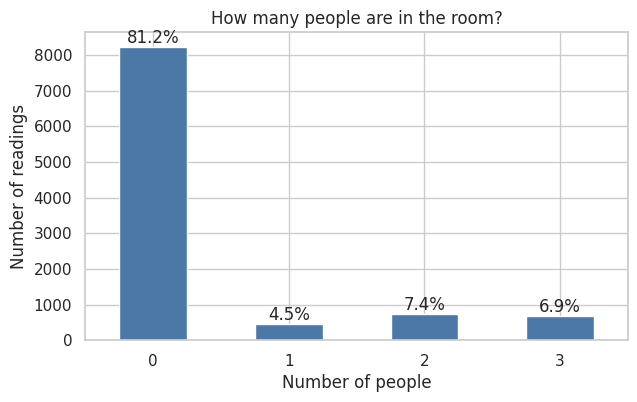

,readings,percent
Room_Occupancy_Count,,
0,8228,81.2
1,459,4.5
2,748,7.4
3,694,6.9


In [38]:
counts = df["Room_Occupancy_Count"].value_counts().sort_index()
percent = counts / counts.sum() * 100

ax = counts.plot(kind="bar", color="#4C78A8", figsize=(7, 4))
for i, (c, p) in enumerate(zip(counts, percent)):
    ax.text(i, c + 100, f"{p:.1f}%", ha="center")
plt.title("How many people are in the room?")
plt.xlabel("Number of people")
plt.ylabel("Number of readings")
plt.xticks(rotation=0)
plt.show()

pd.DataFrame({"readings": counts, "percent": percent.round(1)})

 The room is **empty in 81.2% of the readings**, so a model that always says "empty" would already get 81% accuracy.

### Occupancy over time — when do people arrive and leave?

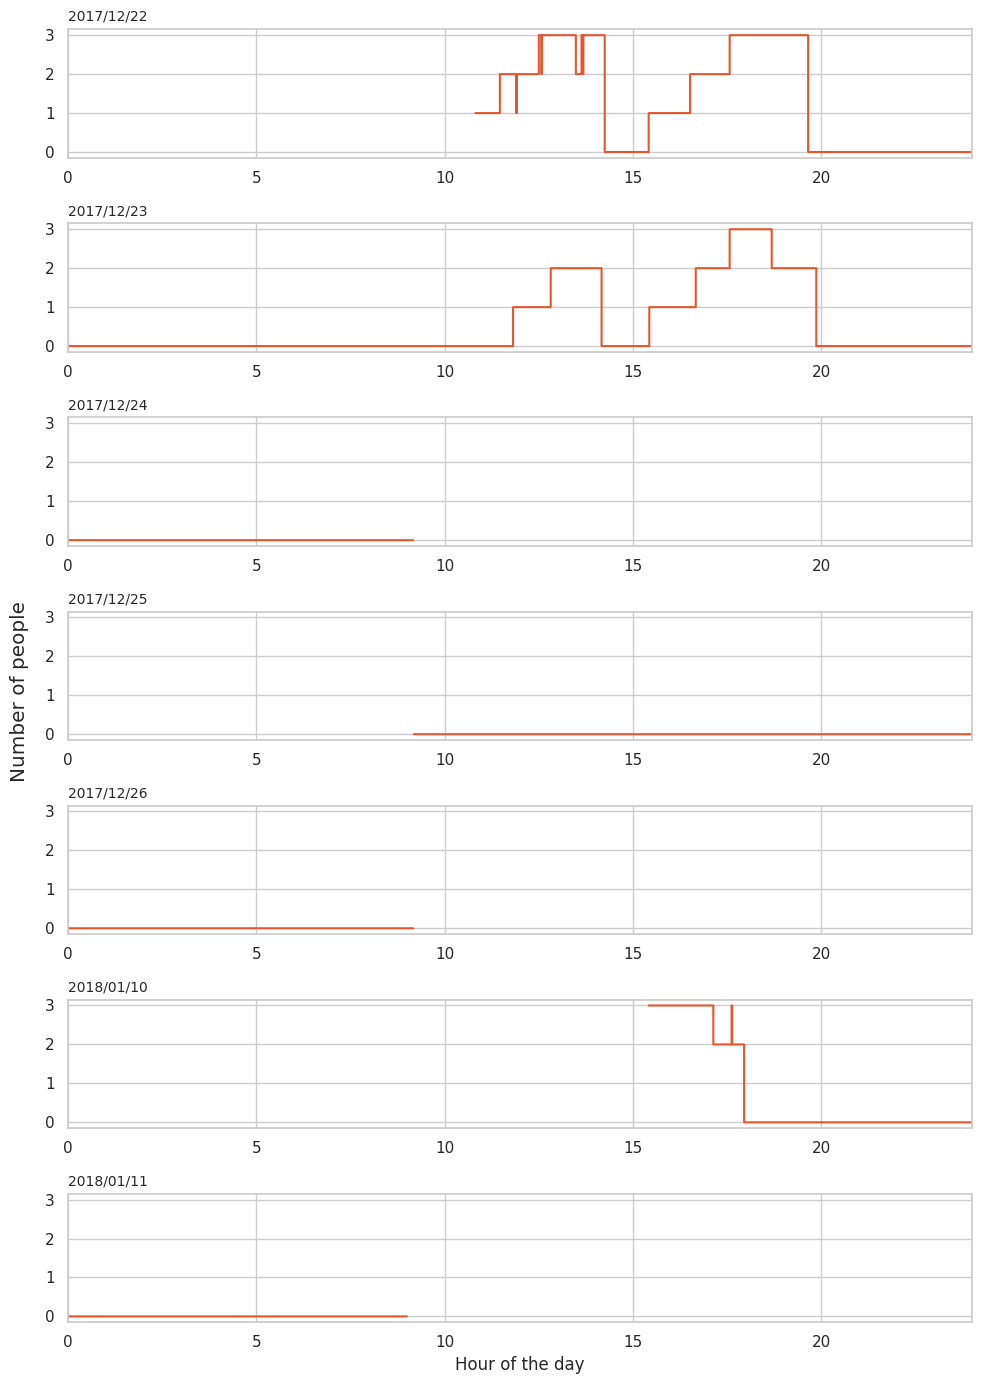

In [39]:
days = sorted(df["Date"].unique())
fig, axes = plt.subplots(len(days), 1, figsize=(10, 2 * len(days)), sharey=True)

for ax, day in zip(axes, days):
    d = df[df["Date"] == day]
    ax.step(d["datetime"].dt.hour + d["datetime"].dt.minute / 60, d["Room_Occupancy_Count"],
            where="post", color="#E4572E")
    ax.set_title(day, loc="left", fontsize=10)
    ax.set_xlim(0, 24)
    ax.set_yticks([0, 1, 2, 3])

axes[-1].set_xlabel("Hour of the day")
fig.supylabel("Number of people")
plt.tight_layout()
plt.show()

In [40]:
occupied = df[df["Room_Occupancy_Count"] > 0]
occupied.groupby("Date")["datetime"].agg(first_person="min", last_person="max")

,first_person,last_person
Date,,
2017/12/22,2017-12-22 10:49:41,2017-12-22 19:36:36
2017/12/23,2017-12-23 11:49:16,2017-12-23 19:51:46
2018/01/10,2018-01-10 15:25:48,2018-01-10 17:56:56


In [41]:
pd.crosstab(df["Date"], df["Room_Occupancy_Count"])

Room_Occupancy_Count,0,1,2,3
Date,,,,
2017/12/22,637,205,257,363
2017/12/23,1997,254,398,130
2017/12/24,1064,0,0,0
2017/12/25,1716,0,0,0
2017/12/26,1063,0,0,0
2018/01/10,703,0,93,201
2018/01/11,1048,0,0,0



1. The room is **empty 81% of the time**, and people are present on **only 3 of the 7 days** (22 Dec, 23 Dec and 10 Jan), mostly between late morning and evening.
2. **Class 1 (one person) is the rarest (4.5%)** and appears **only on 22–23 December**; class 3 is 6.9% and class 2 is 7.4%.



---
# 2.3 · Sensors vs occupancy: plots & correlations
### Boxplots of each sensor per class



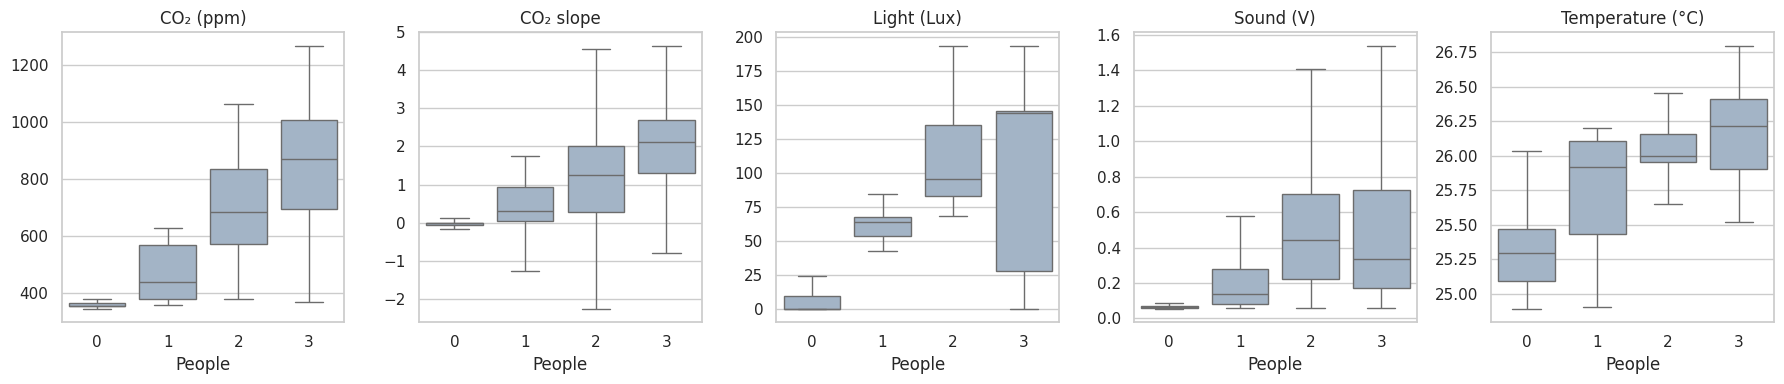

,S5_CO2,S5_CO2_Slope,Light_avg,Sound_avg,Temp_avg
Room_Occupancy_Count,,,,,
0,355.0,0.00,0.00,0.06,25.30
1,440.0,0.30,63.75,0.14,25.92
2,685.0,1.24,95.38,0.44,26.00
3,870.0,2.11,144.38,0.33,26.22


In [42]:
plot_df = df.copy()
plot_df["Temp_avg"] = df[["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"]].mean(axis=1)
plot_df["Light_avg"] = df[["S1_Light", "S2_Light", "S3_Light", "S4_Light"]].mean(axis=1)
plot_df["Sound_avg"] = df[["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]].mean(axis=1)

features = {"S5_CO2": "CO₂ (ppm)", "S5_CO2_Slope": "CO₂ slope", "Light_avg": "Light (Lux)",
            "Sound_avg": "Sound (V)", "Temp_avg": "Temperature (°C)"}

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, (col, label) in zip(axes, features.items()):
    sns.boxplot(x="Room_Occupancy_Count", y=col, data=plot_df, ax=ax, color="#9DB4CC", showfliers=False)
    ax.set_title(label)
    ax.set_xlabel("People")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

plot_df.groupby("Room_Occupancy_Count")[list(features)].median().round(2)

 **CO₂, CO₂ slope and light all go up step by step with the number of people** (median CO₂ 355 → 440 → 685 → 870 ppm; median light 0 → 64 → 95 → 144 Lux). Sound is near zero when the room is empty but does not keep rising from 2 to 3 people, and the boxes for 1, 2 and 3 people overlap for every sensor.



### Outlier check: are there unusual sensor readings?

I used the IQR rule to flag extreme values in the continuous sensor columns. This is only a first check, not a reason to delete rows: high CO₂ or light values can be real readings, and unusual values may be useful for occupancy estimation.

In [43]:
sensor_cols = [
    "S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp",
    "S1_Light", "S2_Light", "S3_Light", "S4_Light",
    "S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound",
    "S5_CO2", "S5_CO2_Slope"
]

outlier_rows = []

for col in sensor_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = (df[col] < lower) | (df[col] > upper)

    outlier_rows.append({
        "Feature": col,
        "Lower bound": round(lower, 2),
        "Upper bound": round(upper, 2),
        "Flagged readings": int(flagged.sum()),
        "Flagged (%)": round(flagged.mean() * 100, 2),
        "IQR is zero": iqr == 0
    })

outlier_summary = pd.DataFrame(outlier_rows).set_index("Feature")
outlier_summary.sort_values("Flagged (%)", ascending=False)

,Lower bound,Upper bound,Flagged readings,Flagged (%),IQR is zero
Feature,,,,,
S5_CO2_Slope,-0.12,0.07,4033,39.82,False
S1_Sound,0.06,0.10,1772,17.49,False
S1_Light,-18.00,30.00,1716,16.94,False
S2_Sound,0.04,0.07,1703,16.81,False
S3_Sound,0.04,0.09,1671,16.50,False
S5_CO2,190.00,630.00,1657,16.36,False
S2_Light,-21.00,35.00,1017,10.04,False
S3_Light,-75.00,125.00,950,9.38,False
S2_Temp,24.53,26.29,948,9.36,False


The IQR rule can flag many readings when a feature has a large number of zeros or a very small IQR, especially for light and sound. I will check the flagged values against the sensor ranges and occupancy patterns before deciding whether anything needs treatment. I will not remove them just because they are outside the IQR limits.

### Compare the four sensor stations

The four stations may capture different parts of the room. I compared their readings separately instead of assuming that averaging them is always better.


Temperature — median by occupancy


,S1_Temp,S2_Temp,S3_Temp,S4_Temp
Room_Occupancy_Count,,,,
0,25.31,25.31,24.88,25.69
1,25.88,25.75,25.50,26.25
2,26.06,26.00,25.69,26.25
3,26.19,26.38,25.88,26.31


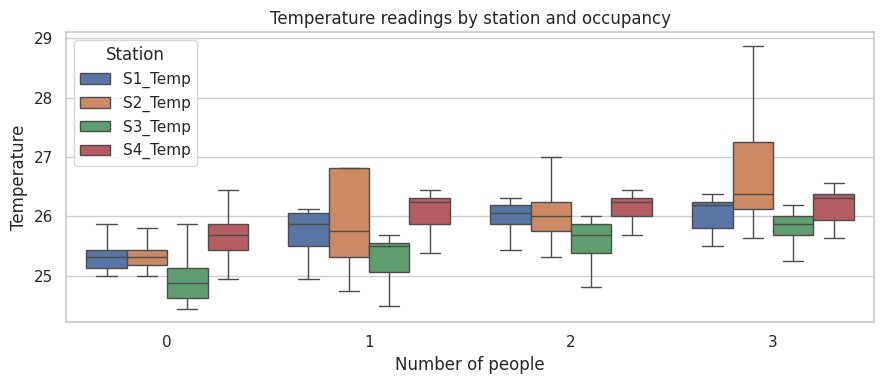


Light — median by occupancy


,S1_Light,S2_Light,S3_Light,S4_Light
Room_Occupancy_Count,,,,
0,0.0,0.0,0.0,0.0
1,120.0,33.0,58.0,40.0
2,142.0,226.0,176.0,19.0
3,149.0,235.0,180.0,12.0


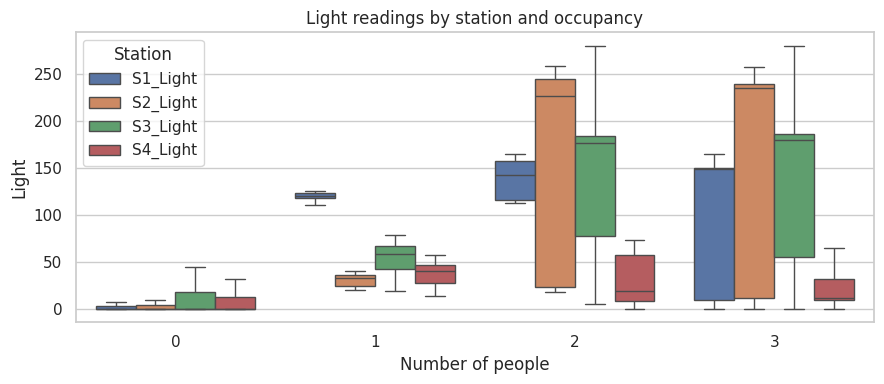


Sound — median by occupancy


,S1_Sound,S2_Sound,S3_Sound,S4_Sound
Room_Occupancy_Count,,,,
0,0.07,0.05,0.06,0.08
1,0.26,0.09,0.08,0.07
2,0.53,0.39,0.30,0.18
3,0.38,0.32,0.26,0.12


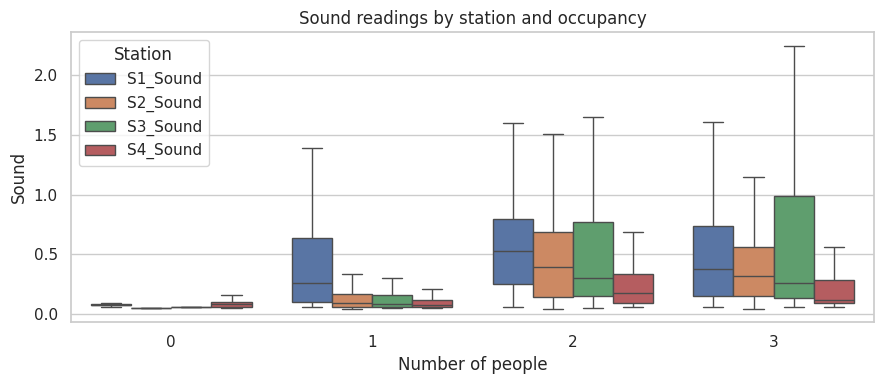

In [44]:
station_groups = {
    "Temperature": ["S1_Temp", "S2_Temp", "S3_Temp", "S4_Temp"],
    "Light": ["S1_Light", "S2_Light", "S3_Light", "S4_Light"],
    "Sound": ["S1_Sound", "S2_Sound", "S3_Sound", "S4_Sound"]
}

for measure, cols in station_groups.items():
    print(f"\n{measure} — median by occupancy")
    display(df.groupby("Room_Occupancy_Count")[cols].median().round(2))

    long_df = df[["Room_Occupancy_Count"] + cols].melt(
        id_vars="Room_Occupancy_Count",
        var_name="Station",
        value_name="Reading"
    )
    plt.figure(figsize=(9, 4))
    sns.boxplot(
        data=long_df,
        x="Room_Occupancy_Count",
        y="Reading",
        hue="Station",
        showfliers=False
    )
    plt.title(f"{measure} readings by station and occupancy")
    plt.xlabel("Number of people")
    plt.ylabel(measure)
    plt.legend(title="Station")
    plt.tight_layout()
    plt.show()

The station comparison helps show whether one sensor is consistently higher or more responsive than the others. If the stations behave differently, keeping the individual readings may preserve useful spatial information. I will only use an average if the comparison shows that it makes sense for the model.

### PIR check: how often is there no motion while people are present?

In [45]:
plot_df["no_motion"] = (df["S6_PIR"] == 0) & (df["S7_PIR"] == 0)
present = plot_df[plot_df["Room_Occupancy_Count"] > 0]

print("Readings with people present:", len(present))
print("...of which BOTH motion sensors show 0:", present["no_motion"].sum(),
      f"({present['no_motion'].mean() * 100:.1f}%)")

pir_table = (pd.crosstab(plot_df["Room_Occupancy_Count"], plot_df["no_motion"], normalize="index") * 100).round(1)
pir_table.columns = ["Motion detected (%)", "No motion (%)"]
pir_table

Readings with people present: 1901
...of which BOTH motion sensors show 0: 727 (38.2%)


,Motion detected (%),No motion (%)
Room_Occupancy_Count,,
0,0.3,99.7
1,35.3,64.7
2,63.9,36.1
3,76.9,23.1


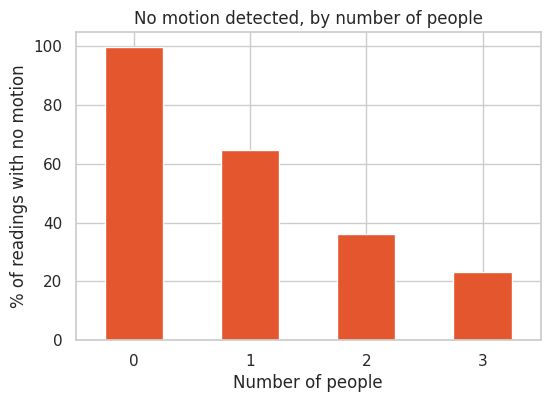

In [46]:
pir_table["No motion (%)"].plot(kind="bar", color="#E4572E", figsize=(6, 4))
plt.title("No motion detected, by number of people")
plt.xlabel("Number of people")
plt.ylabel("% of readings with no motion")
plt.xticks(rotation=0)
plt.show()

 In **38% of the readings with people in the room, neither motion sensor detects anything**, and this rises to **65% when only one person is present**. Motion sensors alone would miss many "quiet" occupants.

### Correlation heatmap of all features

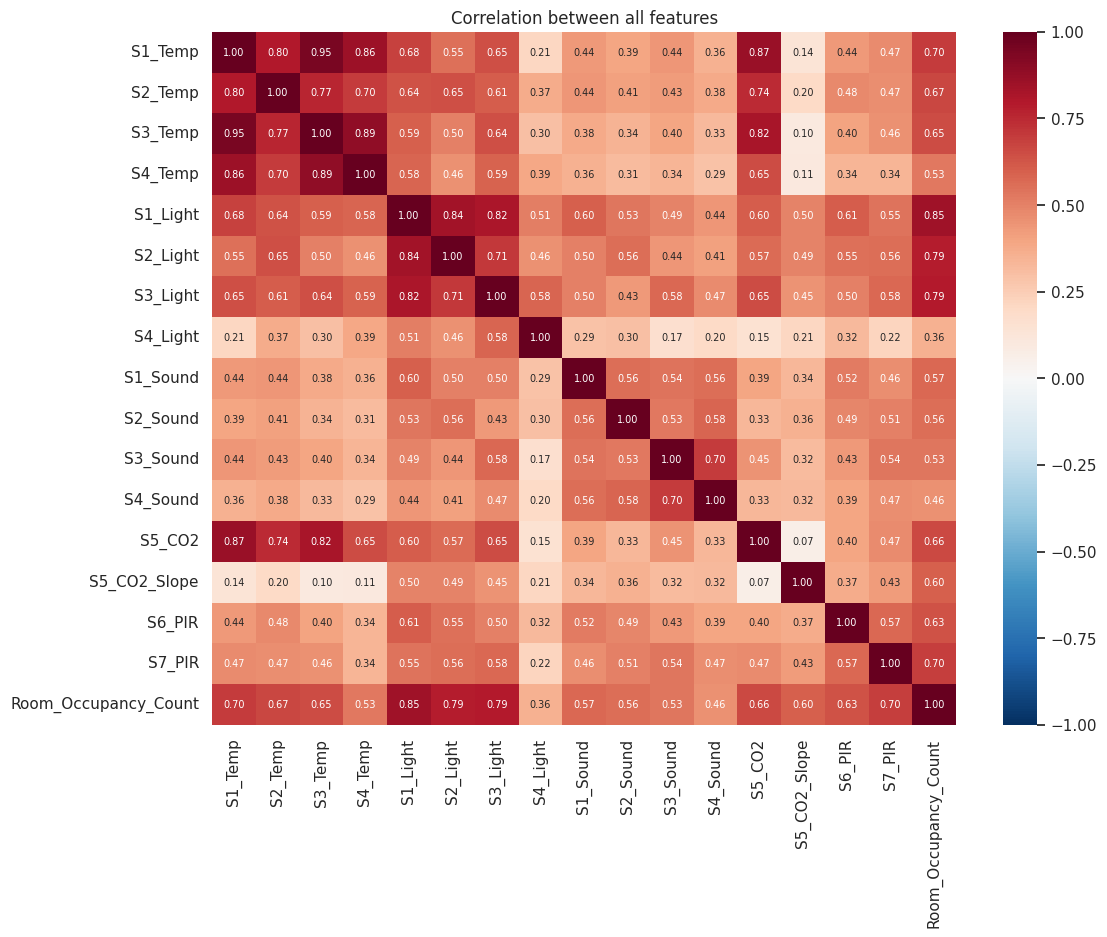

,Room_Occupancy_Count
S1_Light,0.85
S3_Light,0.79
S2_Light,0.79
S1_Temp,0.70
S7_PIR,0.70
S2_Temp,0.67
S5_CO2,0.66
S3_Temp,0.65
S6_PIR,0.63
S5_CO2_Slope,0.60


In [47]:
num_cols = [c for c in df.columns if c not in ["Date", "Time", "datetime"]]
plt.figure(figsize=(12, 9))
sns.heatmap(df[num_cols].corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, annot_kws={"size": 7})
plt.title("Correlation between all features")
plt.show()

df[num_cols].corr()["Room_Occupancy_Count"].drop("Room_Occupancy_Count").sort_values(ascending=False).round(2)

 **Light (S1–S3) has the strongest correlation with the count (0.79–0.85)**, followed by temperature, PIR and CO₂ (0.6–0.7). Sensors of the same type are also strongly correlated with each other, so some of them carry overlapping information.


### One day: CO₂ with the true number of people behind it

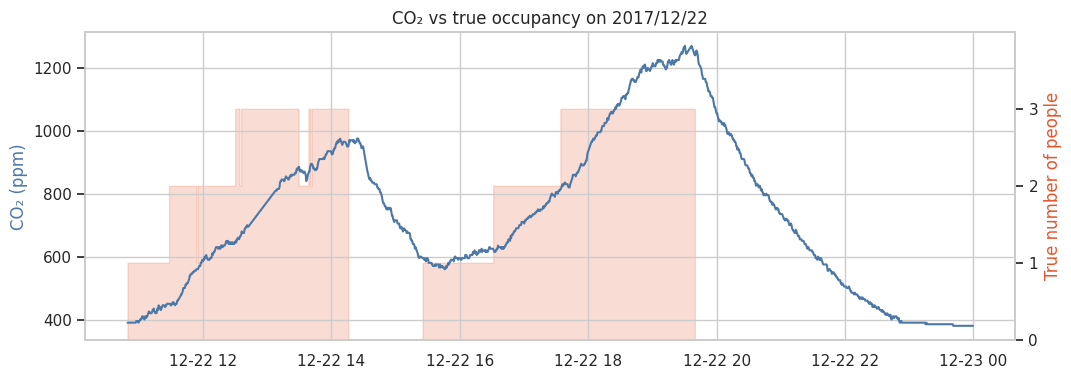

In [48]:
day = "2017/12/22"
d = df[df["Date"] == day]

fig, ax1 = plt.subplots(figsize=(12, 4))
ax2 = ax1.twinx()
ax2.fill_between(d["datetime"], d["Room_Occupancy_Count"], step="post", color="#E4572E", alpha=0.2)
ax2.set_ylabel("True number of people", color="#E4572E")
ax2.set_ylim(0, 4)
ax2.set_yticks([0, 1, 2, 3])
ax2.grid(False)

ax1.plot(d["datetime"], d["S5_CO2"], color="#4C78A8")
ax1.set_ylabel("CO₂ (ppm)", color="#4C78A8")
ax1.set_zorder(ax2.get_zorder() + 1)
ax1.patch.set_visible(False)
plt.title(f"CO₂ vs true occupancy on {day}")
plt.show()

 CO₂ **rises after people enter and keeps falling slowly after they leave**, so it lags behind the true count. This is why the CO₂ **slope** (rising vs falling) adds information that the CO₂ level alone does not.


1. **CO₂ and its slope increase step by step with the number of people**, so they are strong candidates for telling 1, 2 and 3 people apart.
2. **Light has the strongest correlation with the count (0.85)** and is almost 0 when the room is empty, but it depends on people switching the lights on, and the boxes for 2 and 3 people overlap a lot.
3. **Motion sensors miss many occupants**: in 38% of occupied readings (65% with one person), there is no motion at all. This is where CO₂ slope and sound can help.

---
# 2.4 · EDA findings & preprocessing notes

### Main findings

1. **The target is imbalanced:** the room is empty in 81.2% of readings. Accuracy alone will not tell the full story, so I will also check class-wise performance.
2. **The readings are time-dependent:** samples are recorded about every 31 seconds. A random split can put very similar neighboring readings in both train and test, which may make the evaluation look better than it really is.
3. **Class 1 is concentrated in the first two recording days:** the later recording period has no one-person examples. A chronological split may therefore have no class 1 in its test set. This limitation needs to be reported rather than hidden by changing the split just to force all classes into the test set.
4. **Light, CO₂ and CO₂ slope are useful signals,** but no single sensor separates every occupancy class perfectly.
5. **PIR sensors can miss quiet occupants:** both motion sensors are zero in 38.2% of readings where people are present.
6. **CO₂ can lag behind occupancy:** it may remain high after people leave, so its current level should be considered together with its slope and other sensors.
7. **Sensor stations may behave differently:** use the station comparison above before deciding whether to keep individual sensor columns or create averages.

### What this means for preprocessing

- Keep the target `Room_Occupancy_Count` separate from the input features.
- Do not use `Date`, `Time` or `datetime` as ordinary numeric sensor features. Keep `datetime` for ordering and splitting; create time-based features only if there is a clear reason.
- Do not remove IQR-flagged readings automatically. Check whether they are sensor errors or valid events first.
- Do not average the four stations automatically. Compare their distributions and their relationship with occupancy first.
- Decide the train/test split before fitting any preprocessing step. Fit scalers, imputers or feature-selection steps on the training data only.
- Prefer a time-aware evaluation because the rows are sequential. A random split can cause temporal leakage when nearby readings appear on both sides.
- Check class counts after the split. In particular, the later days contain no class 1, so a chronological test set may not represent all four classes.

**EDA is complete.** The next stage is to finalize the split strategy, then build the preprocessing pipeline and compare models. The demo moments should also be selected from the final test set after that split is fixed.

# 3.1 · Train/Test Split

In [49]:

# Sort data by time
df = df.sort_values("datetime").reset_index(drop=True)

# Split by date
test_start = pd.Timestamp("2018-01-10")

train_df = df[df["datetime"] < test_start].copy()
test_df = df[df["datetime"] >= test_start].copy()

# Select features and target
target = "Room_Occupancy_Count"

drop_cols = ["Date", "Time", "datetime", target]
feature_cols = [col for col in df.columns if col not in drop_cols]

X_train = train_df[feature_cols]
X_test = test_df[feature_cols]

y_train = train_df[target]
y_test = test_df[target]

# Check split
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nTraining dates:")
print(train_df["datetime"].min(), "to", train_df["datetime"].max())

print("\nTesting dates:")
print(test_df["datetime"].min(), "to", test_df["datetime"].max())

print("\nTraining class distribution:")
print(y_train.value_counts().reindex([0, 1, 2, 3], fill_value=0))

print("\nTesting class distribution:")
print(y_test.value_counts().reindex([0, 1, 2, 3], fill_value=0))

Training shape: (8084, 16)
Testing shape: (2045, 16)

Training dates:
2017-12-22 10:49:41 to 2017-12-26 09:10:01

Testing dates:
2018-01-10 15:25:48 to 2018-01-11 09:00:09

Training class distribution:
Room_Occupancy_Count
0    6477
1     459
2     655
3     493
Name: count, dtype: int64

Testing class distribution:
Room_Occupancy_Count
0    1751
1       0
2      93
3     201
Name: count, dtype: int64


In [50]:

print("Features:")
print(X_train.columns.tolist())

print("\nData types:")
print(X_train.dtypes)

print("\nTarget:")
print(y_train.value_counts())

Features:
['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']

Data types:
S1_Temp         float64
S2_Temp         float64
S3_Temp         float64
S4_Temp         float64
S1_Light          int64
S2_Light          int64
S3_Light          int64
S4_Light          int64
S1_Sound        float64
S2_Sound        float64
S3_Sound        float64
S4_Sound        float64
S5_CO2            int64
S5_CO2_Slope    float64
S6_PIR            int64
S7_PIR            int64
dtype: object

Target:
Room_Occupancy_Count
0    6477
2     655
3     493
1     459
Name: count, dtype: int64


---
### 3.1b · Chronological evaluation: what this test set can and cannot tell us

The split above is chronological: the models are trained on 22–26 Dec 2017 and tested on 10–11 Jan 2018. This is the honest way to evaluate time-ordered sensor data, but it comes with limits that should be stated next to every test score. The next two cells compute those limits from the data.

In [51]:
# Facts about the chronological split, computed from the data
from sklearn.metrics import f1_score

last_train, first_test = train_df["datetime"].max(), test_df["datetime"].min()
print("Last training reading:", last_train)
print("First test reading:   ", first_test)
print("Gap between them:     ", first_test - last_train)

class_counts = pd.DataFrame({
    "train": y_train.value_counts().reindex([0, 1, 2, 3], fill_value=0),
    "test": y_test.value_counts().reindex([0, 1, 2, 3], fill_value=0),
})
class_counts.index.name = "people"
display(class_counts)

# Macro F1 over labels [0, 1, 2, 3] counts class 1 as F1 = 0 whenever it has no test samples
perfect = f1_score(y_test, y_test, labels=[0, 1, 2, 3], average="macro", zero_division=0)
always_empty = np.zeros(len(y_test), dtype=int)
print("\nBest possible Macro F1 on this test set (labels 0-3):", round(perfect, 3))
print("'Always empty' Macro F1, labels 0-3:                 ",
      round(f1_score(y_test, always_empty, labels=[0, 1, 2, 3], average="macro", zero_division=0), 4))
print("'Always empty' Macro F1, classes present only (4.1): ",
      round(f1_score(y_test, always_empty, average="macro", zero_division=0), 4))

Last training reading: 2017-12-26 09:10:01
First test reading:    2018-01-10 15:25:48
Gap between them:      15 days 06:15:47


,train,test
people,,
0,6477,1751
1,459,0
2,655,93
3,493,201



Best possible Macro F1 on this test set (labels 0-3): 0.75
'Always empty' Macro F1, labels 0-3:                  0.2306
'Always empty' Macro F1, classes present only (4.1):  0.3075


In [52]:
# How much of the test set is "occupied", and does it look like the training sessions?
occ_train = train_df[train_df[target] > 0]
occ_test = test_df[test_df[target] > 0]

print(f"Occupied test readings: {len(occ_test)} of {len(test_df)} ({len(occ_test) / len(test_df):.1%}), "
      f"between {occ_test['datetime'].min()} and {occ_test['datetime'].max()}")

# Lights: how often is somebody present while S1_Light is (almost) off?
LIGHT_OFF_LUX = 15   # any threshold from 10 to 30 lux gives the same counts here
light_check = pd.DataFrame({
    "occupied readings": [len(occ_train), len(occ_test)],
    f"with S1_Light <= {LIGHT_OFF_LUX}": [(occ_train["S1_Light"] <= LIGHT_OFF_LUX).sum(),
                                         (occ_test["S1_Light"] <= LIGHT_OFF_LUX).sum()],
}, index=["train", "test"])
light_check["share (%)"] = (100 * light_check.iloc[:, 1] / light_check.iloc[:, 0]).round(1)
light_check

Occupied test readings: 294 of 2045 (14.4%), between 2018-01-10 15:25:48 and 2018-01-10 17:56:56


,occupied readings,with S1_Light <= 15,share (%)
train,1607,2,0.1
test,294,184,62.6


**What this split gives us**

- **A large time gap.** The last training reading is 26 Dec 2017 09:10 and the first test reading is 10 Jan 2018 15:25, a gap of about 15 days and 6 hours. The test therefore measures how the models behave in a *new recording session*, not in the minutes right after the training data. This is stricter than a random split, which would put near-identical neighbouring readings (30 seconds apart) on both sides.
- **No one-person class in the test set.** All 459 one-person readings are in training (22–23 Dec). On the test set we cannot measure recall or F1 for class 1, nor the confusion between 1 and 2 people. As noted in the EDA findings, we did not change the split just to force class 1 into the test set.
- **Macro F1 is capped at 0.75.** When calculated over the fixed labels `[0, 1, 2, 3]`, class 1 receives an F1 score of 0 because no class-1 observations exist in the January test set. Therefore, the maximum possible four-class Macro F1 is 0.75. The "always empty" baseline now reports a Macro F1 of **0.2306** consistently in Sections 4.1 and 4.2. The previous value of **0.3075** was calculated using only the three classes present in the test set. Both values were mathematically correct under their respective averaging conventions, but we now consistently use all four labels for fair model comparisons.
- **Only one short occupied session.** All 294 occupied test readings (14% of the test set: 201 with 3 people and 93 with 2) fall between 15:25 and 17:57 on 10 Jan. Scores for classes 2 and 3 rest on a single session, so differences of a few points of Macro F1 between models should not be over-interpreted.
- **The test session behaves differently from the training sessions.** In training, only 2 of 1,607 occupied readings have `S1_Light` at or below 15 lux: people were almost always there with the lights on. In the test set it is 184 of 294 (63%): people were in the room with the lights nearly off, during the first part of the session. Models that rely on the light sensors learned that "dark" means "empty", and this explains several results in 4.2 and 4.3.

**The test set has already been used more than once**

The project rule is to leave the test set alone until the final check. In this notebook it has been scored several times:

- the Dummy baseline (4.1);
- the tuned Logistic Regression, KNN and weighted XGBoost models;
- further XGBoost configurations (default settings, with and without class weights), scored after the tuned model during exploration; these cells were later removed from the notebook, but the test set had been looked at;
- the "tricky moments" exploration at the end of the notebook, which looks directly at test rows (a demo-pool listing built from an untuned XGBoost was also viewed and then removed);
- the 12 model × feature-set combinations of the comparison table in 4.2.

The hyperparameters of Logistic Regression, KNN and XGBoost were chosen with time-aware cross-validation on the training days only, and the models in 4.2 use fixed settings, so the tuning itself did not see the test set. Even so, because the test set was looked at repeatedly while comparing models, its scores are best read as **a descriptive check on one unseen session, not as an untouched final hold-out**. The final model choice (5.2) should rest on the whole pattern of evidence, not on small test-score gaps.


### 3.1c — Day-Based Validation

Our chronological test set contains no class-1 samples.

To evaluate all four occupancy classes, we add a
day-based validation experiment using the two
December days containing occupied readings.

- Forward validation: Train on Dec 22, validate on Dec 23.
- Reverse-day check: Train on Dec 23, evaluate on Dec 22.

The forward experiment respects time order.
The reverse experiment is only a robustness check,
not a simulation of predicting the future.

The January test set remains separate.


In [53]:

# Check classes available on each training day
day_distribution = pd.crosstab(
    train_df["Date"],
    train_df["Room_Occupancy_Count"]
)

display(day_distribution)


Room_Occupancy_Count,0,1,2,3
Date,,,,
2017/12/22,637,205,257,363
2017/12/23,1997,254,398,130
2017/12/24,1064,0,0,0
2017/12/25,1716,0,0,0
2017/12/26,1063,0,0,0


In [54]:
LABELS = [0, 1, 2, 3]

# Two separate recording-day experiments
experiments = [
    ("Forward", "2017/12/22", "2017/12/23"),
    ("Reverse (diagnostic)", "2017/12/23", "2017/12/22")
]

results = []

for name, train_day, val_day in experiments:

    train_mask = train_df["Date"] == train_day
    val_mask = train_df["Date"] == val_day

    X_tr = X_train.loc[train_mask]
    y_tr = y_train.loc[train_mask]

    X_val = X_train.loc[val_mask]
    y_val = y_train.loc[val_mask]

    # Fit preprocessing only on training data
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_val)

    # Classification metrics
    macro_f1 = f1_score(
        y_val, y_pred,
        labels=LABELS,
        average="macro",
        zero_division=0
    )

    class_recall = recall_score(
        y_val, y_pred,
        labels=LABELS,
        average=None,
        zero_division=0
    )

    occupied = y_val > 0
    missed_rate = (y_pred[occupied] == 0).mean()

    empty = y_val == 0
    false_alarm_rate = (y_pred[empty] > 0).mean()

    results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_val, y_pred),
        "Macro F1": macro_f1,
        "Class 1 Recall": class_recall[1],
        "Missed Occupancy": missed_rate,
        "False Alarm Rate": false_alarm_rate
    })

    print(f"\n{name}")
    print("Validation class counts:")
    print(y_val.value_counts().reindex(
        LABELS, fill_value=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_val, y_pred, labels=LABELS
    ))

validation_results = pd.DataFrame(results)
display(validation_results.round(3))



Forward
Validation class counts:
Room_Occupancy_Count
0    1997
1     254
2     398
3     130
Name: count, dtype: int64
Confusion Matrix:
[[1995    2    0    0]
 [   0  254    0    0]
 [   0    1  391    6]
 [   0    0    0  130]]

Reverse (diagnostic)
Validation class counts:
Room_Occupancy_Count
0    637
1    205
2    257
3    363
Name: count, dtype: int64
Confusion Matrix:
[[618   0  19   0]
 [  0 202   3   0]
 [  0   2 255   0]
 [  1   0 133 229]]


,Experiment,Accuracy,Macro F1,Class 1 Recall,Missed Occupancy,False Alarm Rate
0,Forward,0.997,0.991,1.000,0.000,0.001
1,Reverse (diagnostic),0.892,0.878,0.985,0.001,0.030



### 3.1c — Validation Findings

**Problem:** The chronological January test set
contains no observations for class 1.

**Solution:** We evaluated the model on separate
December recording days containing all four classes.

**Evaluation strategy:**
1. Chronological January test for later-session performance.
2. Forward day-based validation for all four classes.
3. Reverse-day diagnostic for additional robustness.

**Limitations:**
- Only two recorded days contain all four classes.
- The reverse-day experiment is not forward-time validation.
- January cannot provide class-1 recall.
- January test results have already been examined
  repeatedly and should not be treated as untouched.

**Conclusion:**
We can examine all four classes without mixing
nearby sensor readings between training and
validation, but generalization remains uncertain.


### Day-Based Validation Results

| Metric | Forward | Reverse |
|---|---:|---:|
| Accuracy | 0.997 | 0.892 |
| Macro F1 | 0.991 | 0.878 |
| Class 1 Recall | 1.000 | 0.985 |
| Missed Occupancy | 0.000 | 0.001 |
| False Alarm Rate | 0.001 | 0.030 |

**Interpretation:**

The model performs strongly on both occupied
December recording days, including class 1.

However, performance decreases when evaluated
in the reverse direction and differs substantially
from the January test results.

This indicates that performance depends on the
recording session. Generalization to unseen
sessions remains uncertain.


### 3.2 Feature Sets

In [55]:
# Define feature sets

features_A = ["S5_CO2"]

features_B = [
    "S5_CO2",
    "S5_CO2_Slope"
]

features_C = feature_cols

# Create training and testing data for each set

X_train_A = X_train[features_A]
X_test_A = X_test[features_A]

X_train_B = X_train[features_B]
X_test_B = X_test[features_B]

X_train_C = X_train[features_C]
X_test_C = X_test[features_C]

In [56]:
# Check feature sets
for name, X_tr, X_te in [
    ("A", X_train_A, X_test_A),
    ("B", X_train_B, X_test_B),
    ("C", X_train_C, X_test_C)
]:
    print(f"\nFeature Set {name}")
    print("Training shape:", X_tr.shape)
    print("Testing shape:", X_te.shape)
    print("Features:", X_tr.columns.tolist())


Feature Set A
Training shape: (8084, 1)
Testing shape: (2045, 1)
Features: ['S5_CO2']

Feature Set B
Training shape: (8084, 2)
Testing shape: (2045, 2)
Features: ['S5_CO2', 'S5_CO2_Slope']

Feature Set C
Training shape: (8084, 16)
Testing shape: (2045, 16)
Features: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


### 3.3 Preprocessing Pipeline

In [57]:

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create a separate scaler for each feature set
feature_data = {
    "A": (X_train_A, X_test_A),
    "B": (X_train_B, X_test_B),
    "C": (X_train_C, X_test_C)
}

scalers = {}
scaled_data = {}

for name, (X_tr, X_te) in feature_data.items():

    # Independent scaler for this feature set
    scaler = StandardScaler()

    # Learn mean and std from training data ONLY
    X_tr_scaled = scaler.fit_transform(X_tr)

    # Apply the SAME training statistics to test
    X_te_scaled = scaler.transform(X_te)

    scalers[name] = scaler
    scaled_data[name] = {
        "train": X_tr_scaled,
        "test": X_te_scaled
    }

print("All feature sets scaled successfully!")

All feature sets scaled successfully!


In [58]:

import numpy as np

for name in ["A", "B", "C"]:

    X_tr_scaled = scaled_data[name]["train"]
    X_te_scaled = scaled_data[name]["test"]

    print(f"\nFeature Set {name}")
    print("Training shape:", X_tr_scaled.shape)
    print("Testing shape:", X_te_scaled.shape)

    print(
        "Training mean:",
        np.round(X_tr_scaled.mean(axis=0), 3)
    )

    print(
        "Training std:",
        np.round(X_tr_scaled.std(axis=0), 3)
    )



Feature Set A
Training shape: (8084, 1)
Testing shape: (2045, 1)
Training mean: [0.]
Training std: [1.]

Feature Set B
Training shape: (8084, 2)
Testing shape: (2045, 2)
Training mean: [0. 0.]
Training std: [1. 1.]

Feature Set C
Training shape: (8084, 16)
Testing shape: (2045, 16)
Training mean: [ 0. -0.  0.  0. -0.  0.  0. -0. -0. -0.  0. -0.  0.  0. -0.  0.]
Training std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]



### 3.3 — Preprocessing Findings

**Feature Scaling**

StandardScaler was applied separately to Feature
Sets A, B, and C.

Each scaler was fitted only on the training data.
The same fitted scaler was then used to transform
the corresponding test set.

This prevents leakage of test-set statistics into
the preprocessing step.

**Model Preprocessing**

- Logistic Regression: StandardScaler + Model
- KNN: StandardScaler + Model
- Random Forest: No scaling required
- Gradient Boosting: No scaling required

For cross-validation, preprocessing is fitted
inside each training fold through sklearn Pipeline.

**Class Imbalance**

The target classes are imbalanced, with class 0
representing approximately 81% of observations.

We use class_weight="balanced" for models that
support it, and evaluate using Macro F1 and
missed-occupancy rate.

**Deployment**

The final selected model will be saved together
with its preprocessing pipeline in Step 5.2.


# 4. Modeling

### 4.1 Baseline Model

In [59]:
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    classification_report,
    confusion_matrix
)
from sklearn.model_selection import TimeSeriesSplit

LABELS = [0, 1, 2, 3]

# 1. Train DummyClassifier
baseline_model = DummyClassifier(
    strategy="most_frequent"
)

baseline_model.fit(X_train_C, y_train)

# 2. Predict January test data
baseline_pred = baseline_model.predict(X_test_C)

# 3. Evaluation metrics
baseline_acc = accuracy_score(
    y_test, baseline_pred
)

baseline_macro_f1 = f1_score(
    y_test, baseline_pred,
    labels=LABELS,
    average="macro",
    zero_division=0
)

# Occupied room wrongly predicted as empty
occupied = y_test > 0

missed_occupancy = (
    (baseline_pred[occupied] == 0).mean()
)

# Empty room wrongly predicted as occupied
empty = y_test == 0

false_alarm = (
    (baseline_pred[empty] > 0).mean()
)

# 4. Display metrics
print("=== DummyClassifier Baseline ===")
print(f"Accuracy: {baseline_acc:.4f}")
print(f"Macro F1: {baseline_macro_f1:.4f}")
print(f"Missed Occupancy: {missed_occupancy:.2%}")
print(f"False Alarm Rate: {false_alarm:.2%}")

print("\nPer-Class Recall:")
recalls = recall_score(
    y_test, baseline_pred,
    labels=LABELS,
    average=None,
    zero_division=0
)

for label, recall in zip(LABELS, recalls):
    support = (y_test == label).sum()
    if support == 0:
        print(f"Class {label}: N/A (no test samples)")
    else:
        print(f"Class {label}: {recall:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    baseline_pred,
    labels=LABELS,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test, baseline_pred,
    labels=LABELS
))

# 5. Compute baseline time-series CV score
tscv = TimeSeriesSplit(n_splits=4)
dummy_cv_scores = []

for train_idx, val_idx in tscv.split(X_train_C):

    dummy = DummyClassifier(
        strategy="most_frequent"
    )

    dummy.fit(
        X_train_C.iloc[train_idx],
        y_train.iloc[train_idx]
    )

    pred = dummy.predict(
        X_train_C.iloc[val_idx]
    )

    score = f1_score(
        y_train.iloc[val_idx],
        pred,
        labels=LABELS,
        average="macro",
        zero_division=0
    )

    dummy_cv_scores.append(score)

baseline_cv_f1 = np.mean(dummy_cv_scores)

print(f"\nCV Macro F1: {baseline_cv_f1:.4f}")


=== DummyClassifier Baseline ===
Accuracy: 0.8562
Macro F1: 0.2306
Missed Occupancy: 100.00%
False Alarm Rate: 0.00%

Per-Class Recall:
Class 0: 1.0000
Class 1: N/A (no test samples)
Class 2: 0.0000
Class 3: 0.0000

Classification Report:
              precision    recall  f1-score   support

           0       0.86      1.00      0.92      1751
           1       0.00      0.00      0.00         0
           2       0.00      0.00      0.00        93
           3       0.00      0.00      0.00       201

    accuracy                           0.86      2045
   macro avg       0.21      0.25      0.23      2045
weighted avg       0.73      0.86      0.79      2045


Confusion Matrix:
[[1751    0    0    0]
 [   0    0    0    0]
 [  93    0    0    0]
 [ 201    0    0    0]]

CV Macro F1: 0.2325


### Logistic Regression

In [60]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# Define feature sets
feature_sets = {
    "A": features_A,
    "B": features_B,
    "C": features_C
}

# Time-based cross validation
tscv = TimeSeriesSplit(n_splits=4)

lr_results = []

for name, features in feature_sets.items():

    X = X_train[features]

    fold_scores = []

    for train_idx, val_idx in tscv.split(X):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            ))
        ])

        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)

        score = f1_score(
            y_val,
            y_pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

    lr_results.append({
        "Model": "Logistic Regression",
        "Feature Set": name,
        "Macro F1": np.mean(fold_scores)
    })

lr_results_df = pd.DataFrame(lr_results)

lr_results_df

,Model,Feature Set,Macro F1
0,Logistic Regression,A,0.274205
1,Logistic Regression,B,0.333158
2,Logistic Regression,C,0.552945


In [61]:

# Combine the existing baseline CV results
baseline_results = pd.concat([
    pd.DataFrame([{
        "Model": "DummyClassifier",
        "Feature Set": "C",
        "CV Macro F1": baseline_cv_f1
    }]),
    lr_results_df.rename(
        columns={"Macro F1": "CV Macro F1"}
    )
], ignore_index=True)

display(baseline_results.round(4))


,Model,Feature Set,CV Macro F1
0,DummyClassifier,C,0.2325
1,Logistic Regression,A,0.2742
2,Logistic Regression,B,0.3332
3,Logistic Regression,C,0.5529



### 4.1 — Baseline Evaluation Findings

**DummyClassifier Baseline**

The DummyClassifier always predicts the most
frequent training class (0: Empty).

On the January test set:

- Accuracy: 85.62%
- Macro F1 (labels 0–3): 0.2306
- Missed Occupancy Rate: 100%
- False Alarm Rate: 0%

Although the model achieves high accuracy, it
fails to identify every occupied-room reading.

**Logistic Regression Baseline**

Logistic Regression was evaluated using three
feature sets (A, B, C) with time-aware CV.

Feature Set C achieved the highest average CV
Macro F1 among these Logistic Regression runs.

**Metric Selection**

Primary metric: Macro F1 with labels [0, 1, 2, 3].

Operational metrics:
- Missed Occupancy Rate
- False Alarm Rate
- Per-Class Recall
- Confusion Matrix

**Limitations**

The January test set has no class-1 observations,
so class-1 recall cannot be evaluated there.

Some CV folds also have missing classes.
Day-based validation in Section 3.1c provides
additional evidence for class-1 performance.

We will use these metrics consistently when
comparing models in Section 4.2.


### K-Nearest Neighbors (KNN)

In [62]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

# Define feature sets
feature_sets = {
    "A": features_A,
    "B": features_B,
    "C": features_C
}

# Time-based cross validation
tscv = TimeSeriesSplit(n_splits=4)

knn_results = []

for name, features in feature_sets.items():

    X = X_train[features]
    fold_scores = []

    for train_idx, val_idx in tscv.split(X):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", KNeighborsClassifier(n_neighbors=5))
        ])

        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)

        score = f1_score(
            y_val,
            y_pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

    knn_results.append({
        "Model": "KNN",
        "Feature Set": name,
        "Macro F1": np.mean(fold_scores)
    })

knn_results_df = pd.DataFrame(knn_results)

knn_results_df

,Model,Feature Set,Macro F1
0,KNN,A,0.293430
1,KNN,B,0.394199
2,KNN,C,0.515920


### Random Forest

In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

feature_sets = {
    "A": features_A,
    "B": features_B,
    "C": features_C
}

tscv = TimeSeriesSplit(n_splits=4)

rf_results = []

for name, features in feature_sets.items():

    X = X_train[features]
    fold_scores = []

    for train_idx, val_idx in tscv.split(X):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )

        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)

        score = f1_score(
            y_val,
            y_pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

    rf_results.append({
        "Model": "Random Forest",
        "Feature Set": name,
        "Macro F1": np.mean(fold_scores)
    })

rf_results_df = pd.DataFrame(rf_results)

rf_results_df

,Model,Feature Set,Macro F1
0,Random Forest,A,0.277926
1,Random Forest,B,0.385506
2,Random Forest,C,0.514493


### Gradient Boosting

In [64]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score
import numpy as np
import pandas as pd

feature_sets = {
    "A": features_A,
    "B": features_B,
    "C": features_C
}

tscv = TimeSeriesSplit(n_splits=4)

gb_results = []

for name, features in feature_sets.items():

    X = X_train[features]
    fold_scores = []

    for train_idx, val_idx in tscv.split(X):

        X_tr = X.iloc[train_idx]
        X_val = X.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        model = GradientBoostingClassifier(
            n_estimators=100,
            learning_rate=0.1,
            max_depth=3,
            random_state=42
        )

        model.fit(X_tr, y_tr)

        y_pred = model.predict(X_val)

        score = f1_score(
            y_val,
            y_pred,
            labels=[0, 1, 2, 3],
            average="macro",
            zero_division=0
        )

        fold_scores.append(score)

    gb_results.append({
        "Model": "Gradient Boosting",
        "Feature Set": name,
        "Macro F1": np.mean(fold_scores)
    })

gb_results_df = pd.DataFrame(gb_results)

gb_results_df

,Model,Feature Set,Macro F1
0,Gradient Boosting,A,0.286126
1,Gradient Boosting,B,0.385726
2,Gradient Boosting,C,0.497489


---
### 4.2 Core experiment: all models × feature sets (A, B, C)

The cells above score each model separately. Here all of them are run on the same three feature sets (A = CO₂ only, B = CO₂ + slope, C = all sensors) with the same settings as above (no tuning), so the effect of each layer of information can be read in one table.

- **CV Macro F1:** mean over the four time-aware folds on the training days.
- **Test Macro F1:** on the test days, over labels [0, 1, 2, 3] (see 3.1b for why this is capped at 0.75).
- **Missed occupancy rate:** share of occupied test readings predicted as "empty".
- **False alarm rate:** share of empty test readings predicted as "occupied". It is shown next to missed occupancy because a model that always says "occupied" would never miss anyone.

The full table is saved to `results_experiment.csv` (the existing `results.csv` is not touched).

In [65]:
# 4.2 Core experiment: 4 models x 3 feature sets, same settings as the cells above
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

LABELS = [0, 1, 2, 3]
MODELS = ["Logistic Regression", "KNN", "Random Forest", "Gradient Boosting"]
feature_sets = {"A": features_A, "B": features_B, "C": features_C}

def make_model(name):
    if name == "Dummy (most frequent)":
        return DummyClassifier(strategy="most_frequent")
    if name == "Logistic Regression":
        return Pipeline([("scaler", StandardScaler()),
                         ("model", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42))])
    if name == "KNN":
        return Pipeline([("scaler", StandardScaler()),
                         ("model", KNeighborsClassifier(n_neighbors=5))])
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1)
    if name == "Gradient Boosting":
        return GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)

def score_macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, labels=LABELS, average="macro", zero_division=0)

tscv = TimeSeriesSplit(n_splits=4)
occupied_test = y_test > 0
rows, cv_pred, test_pred = [], {}, {}

for model_name in ["Dummy (most frequent)"] + MODELS:
    for set_name, cols in feature_sets.items():
        X_tr, X_te = X_train[cols], X_test[cols]

        # time-aware CV on the training days only; out-of-fold predictions are kept for Q1 and Q2
        oof = pd.Series(np.nan, index=X_tr.index)
        fold_scores = []
        for tr_idx, val_idx in tscv.split(X_tr):
            model = make_model(model_name).fit(X_tr.iloc[tr_idx], y_train.iloc[tr_idx])
            oof.iloc[val_idx] = model.predict(X_tr.iloc[val_idx])
            fold_scores.append(score_macro_f1(y_train.iloc[val_idx], oof.iloc[val_idx]))
        cv_pred[(model_name, set_name)] = oof

        # fit on all training days, score on the test days
        model = make_model(model_name).fit(X_tr, y_train)
        pred = pd.Series(model.predict(X_te), index=X_te.index)
        test_pred[(model_name, set_name)] = pred

        rows.append({
            "Model": model_name,
            "Feature Set": set_name,
            "CV Macro F1": np.mean(fold_scores),
            "Test Macro F1": score_macro_f1(y_test, pred),
            "Test Missed Occupancy": int(((pred == 0) & occupied_test).sum()),
            "Test Missed Occupancy Rate": ((pred == 0) & occupied_test).sum() / occupied_test.sum(),
            "Test False Alarm Rate": ((pred > 0) & ~occupied_test).sum() / (~occupied_test).sum(),
        })

cv_mask = cv_pred[("KNN", "A")].notna()      # training rows that were part of a validation fold
experiment_results = pd.DataFrame(rows)
experiment_results.to_csv("results_experiment.csv", index=False)

metrics = ["CV Macro F1", "Test Macro F1", "Test Missed Occupancy Rate", "Test False Alarm Rate"]
comparison = (experiment_results
              .pivot(index="Model", columns="Feature Set", values=metrics)
              .reindex(["Dummy (most frequent)"] + MODELS)
              .round(3))
comparison

CV Macro F1               Test Macro F1                \
Feature Set                     A      B      C             A      B      C   
Model                                                                         
Dummy (most frequent)       0.233  0.233  0.233         0.231  0.231  0.231   
Logistic Regression         0.274  0.333  0.553         0.324  0.436  0.424   
KNN                         0.293  0.394  0.516         0.280  0.349  0.304   
Random Forest               0.278  0.386  0.514         0.271  0.373  0.408   
Gradient Boosting           0.286  0.386  0.497         0.240  0.345  0.305   

                      Test Missed Occupancy Rate                \
Feature Set                                    A      B      C   
Model                                                            
Dummy (most frequent)                      1.000  1.000  1.000   
Logistic Regression                        0.228  0.058  0.626   
KNN                                        0.558  0.020  0.129   
Random Forest                              0.000  0.010  0.626   
Gradient Boosting                          0.541  0.085  0.626   

                      Test False Alarm Rate                
Feature Set                               A      B      C  
Model                                                      
Dummy (most frequent)                 0.000  0.000  0.000  
Logistic Regression                   0.132  0.058  0.000  
KNN                                   0.105  0.017  0.001  
Random Forest                         0.234  0.016  0.000  
Gradient Boosting                     0.071  0.014  0.000

In [66]:

# 4.2b — Forward day-based comparison
# Train: December 22
# Validate: December 23

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score
)
import pandas as pd
import numpy as np

train_mask = (
    train_df["Date"] == "2017/12/22"
)
val_mask = (
    train_df["Date"] == "2017/12/23"
)

y_tr = y_train.loc[train_mask]
y_val = y_train.loc[val_mask]

print("Training class distribution:")
print(y_tr.value_counts().reindex(
    LABELS, fill_value=0
))

print("\nValidation class distribution:")
print(y_val.value_counts().reindex(
    LABELS, fill_value=0
))

forward_rows = []

for model_name in MODELS:
    for set_name, cols in feature_sets.items():

        X_tr = X_train.loc[train_mask, cols]
        X_val = X_train.loc[val_mask, cols]

        # Fresh model for each experiment
        model = make_model(model_name)

        model.fit(X_tr, y_tr)
        y_pred = model.predict(X_val)

        occupied = y_val > 0
        empty = y_val == 0

        missed_rate = (
            (y_pred[occupied] == 0).mean()
        )

        false_alarm_rate = (
            (y_pred[empty] > 0).mean()
        )

        recalls = recall_score(
            y_val,
            y_pred,
            labels=LABELS,
            average=None,
            zero_division=0
        )

        forward_rows.append({
            "Model": model_name,
            "Feature Set": set_name,
            "Accuracy": accuracy_score(
                y_val, y_pred
            ),
            "Macro F1": f1_score(
                y_val,
                y_pred,
                labels=LABELS,
                average="macro",
                zero_division=0
            ),
            "Class 1 Recall": recalls[1],
            "Missed Occupancy Rate": missed_rate,
            "False Alarm Rate": false_alarm_rate
        })

forward_results = pd.DataFrame(
    forward_rows
)

display(forward_results.round(4))

forward_results.to_csv(
    "results_forward_validation.csv",
    index=False
)


Training class distribution:
Room_Occupancy_Count
0    637
1    205
2    257
3    363
Name: count, dtype: int64

Validation class distribution:
Room_Occupancy_Count
0    1997
1     254
2     398
3     130
Name: count, dtype: int64


,Model,Feature Set,Accuracy,Macro F1,Class 1 Recall,Missed Occupancy Rate,False Alarm Rate
0,Logistic Regression,A,0.1749,0.2283,1.0000,0.1202,0.9599
1,Logistic Regression,B,0.3203,0.4048,0.7677,0.0716,0.7957
2,Logistic Regression,C,0.9968,0.9905,1.0000,0.0000,0.0010
3,KNN,A,0.6826,0.4134,0.1732,0.4795,0.1487
4,KNN,B,0.8165,0.6575,0.4370,0.2864,0.0461
5,KNN,C,0.8190,0.8249,0.9685,0.0000,0.2394
6,Random Forest,A,0.6538,0.3841,0.1417,0.4143,0.1803
7,Random Forest,B,0.7711,0.6260,0.5118,0.2417,0.1217
8,Random Forest,C,0.9500,0.9117,1.0000,0.1330,0.0005
9,Gradient Boosting,A,0.6859,0.3753,0.1142,0.5269,0.1182


In [67]:
# Compare feature sets A, B, C
# using forward validation Macro F1

forward_comparison = (
    forward_results.pivot(
        index="Model",
        columns="Feature Set",
        values="Macro F1"
    )
    .reindex(MODELS)
    .round(4)
)

display(forward_comparison)

# Compare missed occupancy rates
forward_missed = (
    forward_results.pivot(
        index="Model",
        columns="Feature Set",
        values="Missed Occupancy Rate"
    )
    .reindex(MODELS)
    .round(4)
)

print("Forward validation missed occupancy:")
display(forward_missed)


Feature Set,A,B,C
Model,,,
Logistic Regression,0.2283,0.4048,0.9905
KNN,0.4134,0.6575,0.8249
Random Forest,0.3841,0.6260,0.9117
Gradient Boosting,0.3753,0.6339,0.8087


Forward validation missed occupancy:


Feature Set,A,B,C
Model,,,
Logistic Regression,0.1202,0.0716,0.000
KNN,0.4795,0.2864,0.000
Random Forest,0.4143,0.2417,0.133
Gradient Boosting,0.5269,0.2852,0.000


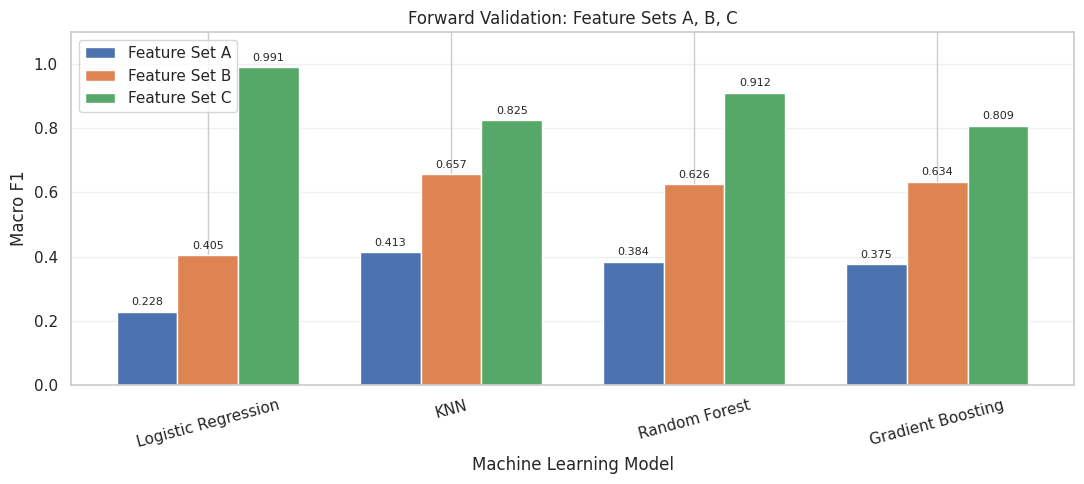

In [68]:
# Forward validation results
chart_data = forward_comparison

x = np.arange(len(MODELS))
width = 0.25

plt.figure(figsize=(11, 5))

for i, set_name in enumerate(["A", "B", "C"]):

    values = chart_data[set_name].values

    bars = plt.bar(
        x + (i - 1) * width,
        values,
        width,
        label=f"Feature Set {set_name}"
    )

    plt.bar_label(
        bars,
        fmt="%.3f",
        padding=3,
        fontsize=8
    )

plt.xticks(x, MODELS, rotation=15)

plt.ylabel("Macro F1")
plt.xlabel("Machine Learning Model")

plt.title(
    "Forward Validation: Feature Sets A, B, C"
)

plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()



### 4.2 — Model Comparison Findings

**Experiment Overview**

Four machine learning models were evaluated:

1. Logistic Regression
2. K-Nearest Neighbors (KNN)
3. Random Forest
4. Gradient Boosting

Each model was trained using three feature sets:

- A: CO2 only
- B: CO2 and CO2 slope
- C: All 16 sensor features

**Evaluation Strategy**

We compared models using:

1. Four-fold TimeSeriesSplit on December training data.
2. Forward-day validation (December 22 to 23).
3. January test results as a descriptive,
   previously examined session check.

The forward-day validation contains all four
occupancy classes.

**Existing Time-Series CV Findings**

Feature Set C achieved the highest average
four-fold CV Macro F1 for all four models.

Logistic Regression with Feature Set C
achieved the highest average CV Macro F1
of approximately 0.553.

However, some CV validation folds contain
only empty-room observations.


**Forward-Day Validation Findings**

Feature Set C achieved the highest Macro F1
for all four models on December 23.

Logistic Regression achieved the highest
Macro F1 of 0.9905, followed by:

- Random Forest: 0.9117
- KNN: 0.8249
- Gradient Boosting: 0.8087

Using Feature Set C, Logistic Regression,
KNN, and Gradient Boosting achieved 0%
missed occupancy in this validation session.

Random Forest had a missed occupancy
rate of 13.30%.

These results suggest that additional sensors
improve classification on the December session.
However, performance on the January session
is substantially different, so the results
should not be assumed to generalize.


**January Session Findings**

Feature Set B showed lower missed occupancy
than Feature Set C for all four models.

The January session also contained occupied
readings with very low light levels, unlike
most occupied December readings.

This suggests a distribution shift that may
affect models relying on light-related features.

However, this does not prove that lighting
alone caused the performance difference.

**Conclusion**

Model selection should consider:

- Macro F1
- Missed Occupancy Rate
- False Alarm Rate
- Per-Class Recall
- Generalization across recording sessions

The January results are descriptive because
the test set has already been examined repeatedly.

The final model will be selected in Section 5.2.


#### Q1 · Does the CO₂ slope help detect the quiet occupant?

"Quiet" means people are present but **both PIR motion sensors read 0**. We compare set A (CO₂ level only) with set B (CO₂ level + slope), using the same models and settings. Two kinds of evidence are shown: out-of-fold predictions from the time-aware CV on the training days (this is the only place with one-person readings), and the test days (quiet occupants with 2 or 3 people).

In [69]:
# Q1: does adding the CO2 slope (set B vs set A) help detect the quiet occupant?
# "Quiet" = somebody is present but both PIR motion sensors read 0.
quiet_train = (X_train["S6_PIR"] == 0) & (X_train["S7_PIR"] == 0) & (y_train > 0)
quiet_test = (X_test["S6_PIR"] == 0) & (X_test["S7_PIR"] == 0) & (y_test > 0)

quiet_cv = cv_mask & quiet_train                 # quiet readings that have an out-of-fold prediction
quiet_one_cv = quiet_cv & (y_train == 1)         # ... of which exactly one person
empty_cv = cv_mask & (y_train == 0)

print("Quiet occupied readings in the CV validation folds:", int(quiet_cv.sum()),
      "| of which one person:", int(quiet_one_cv.sum()),
      "| dates:", sorted(train_df.loc[quiet_one_cv, "Date"].unique()))
print("Quiet occupied readings in the test days:", int(quiet_test.sum()),
      "| classes:", y_test[quiet_test].value_counts().sort_index().to_dict(), "(no one-person readings)")

def pct(mask_true):
    return round(100 * mask_true.mean(), 1)

q1_rows = []
for model_name in MODELS:
    for set_name in ["A", "B"]:
        p_cv, p_te = cv_pred[(model_name, set_name)], test_pred[(model_name, set_name)]
        q1_rows.append({
            "Model": model_name, "Set": set_name,
            "CV: quiet occupants detected (%)": pct(p_cv[quiet_cv] > 0),
            "CV: quiet 1-person detected (%)": pct(p_cv[quiet_one_cv] > 0),
            "CV: quiet 1-person exactly '1' (%)": pct(p_cv[quiet_one_cv] == 1),
            "CV: false alarms on empty (%)": pct(p_cv[empty_cv] > 0),
            "Test: quiet occupants detected (%)": pct(p_te[quiet_test] > 0),
            "Test: false alarms on empty (%)": pct(p_te[~occupied_test] > 0),
        })
q1_table = (pd.DataFrame(q1_rows)
            .set_index(["Model", "Set"]))
q1_table

Quiet occupied readings in the CV validation folds: 410 | of which one person: 157 | dates: ['2017/12/23']
Quiet occupied readings in the test days: 59 | classes: {2: 15, 3: 44} (no one-person readings)


CV: quiet occupants detected (%)  \
Model               Set                                     
Logistic Regression A                                83.9   
                    B                                92.0   
KNN                 A                                55.4   
                    B                                60.5   
Random Forest       A                                70.5   
                    B                                67.1   
Gradient Boosting   A                                46.8   
                    B                                72.7   

                         CV: quiet 1-person detected (%)  \
Model               Set                                    
Logistic Regression A                               71.3   
                    B                               84.7   
KNN                 A                               27.4   
                    B                               63.1   
Random Forest       A                               51.0   
                    B                               77.7   
Gradient Boosting   A                               21.7   
                    B                               75.2   

                         CV: quiet 1-person exactly '1' (%)  \
Model               Set                                       
Logistic Regression A                                  63.7   
                    B                                  58.0   
KNN                 A                                  10.8   
                    B                                  30.6   
Random Forest       A                                  12.7   
                    B                                  44.6   
Gradient Boosting   A                                  10.8   
                    B                                  39.5   

                         CV: false alarms on empty (%)  \
Model               Set                                  
Logistic Regression A                             27.8   
                    B                             23.1   
KNN                 A                              5.3   
                    B                              1.5   
Random Forest       A                             11.5   
                    B                              4.4   
Gradient Boosting   A                              4.1   
                    B                              3.2   

                         Test: quiet occupants detected (%)  \
Model               Set                                       
Logistic Regression A                                  78.0   
                    B                                  93.2   
KNN                 A                                  39.0   
                    B                                  96.6   
Random Forest       A                                 100.0   
                    B                                  98.3   
Gradient Boosting   A                                  45.8   
                    B                                  96.6   

                         Test: false alarms on empty (%)  
Model               Set                                   
Logistic Regression A                               13.2  
                    B                                5.8  
KNN                 A                               10.5  
                    B                                1.7  
Random Forest       A                               23.4  
                    B                                1.6  
Gradient Boosting   A                                7.1  
                    B                                1.4

**Answer: yes, mostly.**

- **Quiet one-person readings (time-aware CV).** The share predicted as occupied rises for all four models: Logistic Regression 71% → 85%, KNN 27% → 63%, Random Forest 51% → 83%, Gradient Boosting 22% → 75%.
- **Quiet occupants in the test days (59 readings, classes 2 and 3).** Detection rises from 78% to 93% (Logistic Regression), 39% to 97% (KNN) and 46% to 97% (Gradient Boosting). Random Forest already detects almost all of them with set A (100% → 98%), but only by flagging many empty readings (about 23% false alarms with A, 3% with B).
- **False alarms do not go up.** The false-alarm rate on empty readings is lower with the slope for every model, in CV and on the test days, so the gain does not come from simply predicting "occupied" more often.
- **Exact counts are a different story.** Predicting exactly "1" for quiet one-person readings improves for KNN, Random Forest and Gradient Boosting (from 11–15% to 31–46%) but not for Logistic Regression (64% → 58%). For all quiet readings of any count, Random Forest is also a small exception (75% → 71%). The slope helps mainly to decide *occupied or empty*, less to count one person precisely.

Why it works: a person sitting still keeps adding CO₂, so the level may still look low while the slope is already positive. The level alone cannot separate that from an empty room with the same CO₂, which is the 390 ppm puzzle from the EDA.

Limits: the 157 quiet one-person readings come from a single day (23 Dec), because the first CV training fold already covers 22 Dec, and the test days contain no one-person readings.

#### Q2 · Does adding all remaining sensors reduce confusion between 1 and 2 people?
We compare set B (CO₂ + slope) with set C (all sensors). The test days have no one-person readings, so this question can only be answered on the training days. The table shows two evaluations: the same time-aware CV predictions as above, and a leave-one-day-out check on the two training days that have 1 or 2 people (22 and 23 Dec; each day is predicted by a model trained on the other days, so this one is not chronological and is used only as a robustness check). Columns show what happens to the 1- and 2-person readings: confused with each other, predicted empty, or counted exactly.

In [70]:
# Q2: Does Feature Set C reduce confusion
# between 1 and 2 people compared with B?
# The test days contain no one-person readings, so this is answered on the training days only,
# in two ways: (a) the same time-aware CV predictions as above, (b) leave-one-day-out on the two
# training days that have 1 or 2 people (not chronological, used only as a robustness check).
in_12 = y_train.isin([1, 2])
days_12 = sorted(train_df.loc[in_12, "Date"].unique())
print("Days with 1 or 2 people in training:", days_12)

lodo_pred = {}
for model_name in MODELS:
    for set_name in ["B", "C"]:
        cols = feature_sets[set_name]
        pred = pd.Series(np.nan, index=X_train.index)
        for day in days_12:
            held_out = (train_df["Date"] == day).values
            model = make_model(model_name).fit(X_train.loc[~held_out, cols], y_train[~held_out])
            pred[held_out] = model.predict(X_train.loc[held_out, cols])
        lodo_pred[(model_name, set_name)] = pred

def one_vs_two(pred, mask):
    y, p = y_train[mask], pred[mask]
    return {"readings": int(mask.sum()),
            "1 -> 2 (%)": round(100 * ((y == 1) & (p == 2)).sum() / mask.sum(), 1),
            "2 -> 1 (%)": round(100 * ((y == 2) & (p == 1)).sum() / mask.sum(), 1),
            "predicted empty (%)": round(100 * (p == 0).mean(), 1),
            "exact count (%)": round(100 * (p == y).mean(), 1)}

q2_rows = []
for evaluation, preds, mask in [("time-aware CV", cv_pred, in_12 & cv_mask),
                                ("leave-one-day-out", lodo_pred, in_12)]:
    for model_name in MODELS:
        for set_name in ["B", "C"]:
            q2_rows.append({"Evaluation": evaluation, "Model": model_name, "Set": set_name,
                            **one_vs_two(preds[(model_name, set_name)], mask)})
q2_table = pd.DataFrame(q2_rows).set_index(["Evaluation", "Model", "Set"])
display(q2_table)

# Where could the separation come from? Median sensor levels for 1 vs 2 people (training days)
sep_cols = ["S1_Light", "S2_Light", "S3_Light", "S1_Sound", "S2_Sound", "S3_Sound", "S5_CO2", "S5_CO2_Slope"]
train_df[in_12].groupby(target)[sep_cols].median().round(2)

Days with 1 or 2 people in training: ['2017/12/22', '2017/12/23']


readings  1 -> 2 (%)  2 -> 1 (%)  \
Evaluation        Model               Set                                     
time-aware CV     Logistic Regression B         652        10.4         8.9   
                                      C         652         0.0         0.2   
                  KNN                 B         652        11.8        11.0   
                                      C         652         1.4         1.5   
                  Random Forest       B         652        12.3         9.7   
                                      C         652         0.0         0.0   
                  Gradient Boosting   B         652        13.2         9.0   
                                      C         652         2.9         0.3   
leave-one-day-out Logistic Regression B        1114         9.1         5.3   
                                      C        1114         0.3         0.3   
                  KNN                 B        1114        11.3        10.5   
                                      C        1114         1.2         0.9   
                  Random Forest       B        1114        14.0         6.7   
                                      C        1114         1.6         0.0   
                  Gradient Boosting   B        1114        15.7         7.1   
                                      C        1114         0.4         0.3   

                                           predicted empty (%)  \
Evaluation        Model               Set                        
time-aware CV     Logistic Regression B                    6.7   
                                      C                    0.0   
                  KNN                 B                   39.7   
                                      C                    0.0   
                  Random Forest       B                   32.8   
                                      C                   29.3   
                  Gradient Boosting   B                   28.2   
                                      C                    0.0   
leave-one-day-out Logistic Regression B                   19.7   
                                      C                    0.0   
                  KNN                 B                   37.2   
                                      C                    0.1   
                  Random Forest       B                   38.7   
                                      C                    7.2   
                  Gradient Boosting   B                   39.2   
                                      C                    0.0   

                                           exact count (%)  
Evaluation        Model               Set                   
time-aware CV     Logistic Regression B               52.9  
                                      C               96.2  
                  KNN                 B               35.3  
                                      C               95.9  
                  Random Forest       B               42.5  
                                      C               69.9  
                  Gradient Boosting   B               42.5  
                                      C               77.6  
leave-one-day-out Logistic Regression B               51.0  
                                      C               99.4  
                  KNN                 B               33.6  
                                      C               95.6  
                  Random Forest       B               34.4  
                                      C               84.2  
                  Gradient Boosting   B               32.3  
                                      C               85.3

,S1_Light,S2_Light,S3_Light,S1_Sound,S2_Sound,S3_Sound,S5_CO2,S5_CO2_Slope
Room_Occupancy_Count,,,,,,,,
1,120.0,33.0,58.0,0.26,0.09,0.08,440.0,0.30
2,119.0,26.0,179.0,0.58,0.39,0.31,645.0,1.32


**Answer: Adding all remaining sensors (Feature Set C) substantially reduces confusion between one-person and two-person readings during the December validation experiments. However, we cannot attribute this improvement specifically to sound or light without additional feature-ablation experiments.**
- **Confusion between 1 and 2 almost disappears with set C.** With set B, about 19–23% of the one- and two-person readings are confused with each other (1 → 2 or 2 → 1) in time-aware CV, and 14–23% under leave-one-day-out. With set C it falls to 0–3% in CV and to about 2% or less under leave-one-day-out.
- **Set B has a second problem that set C mostly fixes.** With B, 7–40% of these readings are predicted *empty* in CV (CO₂ lags behind the people in the room). With Feature Set C, the proportion predicted as empty is close to 0% for most models. However, Random Forest still predicts **29.3%** of these readings as empty during time-aware cross-validation and **7.2%** during the leave-one-day-out diagnostic.
- **Possible sources of separation.** During the training days, one- and two-person readings show differences in light, sound, and CO₂ measurements. For example, median light at S3 increases from 58 to 179 lux, while median sound at S1 increases from 0.26 to 0.58 V. However, because Feature Set C adds several sensors simultaneously, we cannot determine which individual sensor is responsible for the improvement.
- **Caution.** The evidence comes from two days of the same December recording period, and the test days contain no one-person readings. We cannot yet say that light and sound will separate 1 from 2 people in a new session, and 3.1b shows that the light pattern can change between sessions (people present with the lights nearly off).

### Logistic Regression Tuning

In [71]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from scipy.stats import loguniform

lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

lr_params = {
    "model__C": loguniform(0.001, 100)
}

tscv = TimeSeriesSplit(n_splits=4)

lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_params,
    n_iter=10,
    scoring="f1_macro",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

lr_search.fit(X_train_C, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best CV Macro F1:", lr_search.best_score_)

Best Parameters: {'model__C': np.float64(1.0129197956845732)}
Best CV Macro F1: 0.9912292916809716


In [72]:
from sklearn.metrics import make_scorer, f1_score

macro_f1_scorer = make_scorer(
    f1_score,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
)

In [73]:
lr_search = RandomizedSearchCV(
    estimator=lr_pipeline,
    param_distributions=lr_params,
    n_iter=10,
    scoring=macro_f1_scorer,
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

lr_search.fit(X_train_C, y_train)

print("Best Parameters:", lr_search.best_params_)
print("Best CV Macro F1:", lr_search.best_score_)

Best Parameters: {'model__C': np.float64(1.0129197956845732)}
Best CV Macro F1: 0.5539820959495831


### K-Nearest Neighbors (KNN) Tuning

In [74]:
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

knn_params = {
    "model__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
    "model__weights": ["uniform", "distance"],
    "model__p": [1, 2]
}

knn_search = RandomizedSearchCV(
    estimator=knn_pipeline,
    param_distributions=knn_params,
    n_iter=10,
    scoring="f1_macro",
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

knn_search.fit(X_train_C, y_train)

print("Best Parameters:", knn_search.best_params_)
print("Best CV Macro F1:", knn_search.best_score_)

Best Parameters: {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 21}
Best CV Macro F1: 0.8338360931340764


In [75]:
knn_search = RandomizedSearchCV(
    estimator=knn_pipeline,
    param_distributions=knn_params,
    n_iter=10,
    scoring=macro_f1_scorer,
    cv=tscv,
    random_state=42,
    n_jobs=-1
)

knn_search.fit(X_train_C, y_train)

print("Best Parameters:", knn_search.best_params_)
print("Best CV Macro F1:", knn_search.best_score_)

Best Parameters: {'model__weights': 'distance', 'model__p': 1, 'model__n_neighbors': 21}
Best CV Macro F1: 0.5297920478524135


In [76]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

best_models = {
    "Logistic Regression": lr_search.best_estimator_,
    "KNN": knn_search.best_estimator_
}

final_results = []

for name, model in best_models.items():

    y_pred = model.predict(X_test_C)

    accuracy = accuracy_score(y_test, y_pred)

    macro_f1 = f1_score(
        y_test, y_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_test, y_pred,
        average="weighted",
        zero_division=0
    )

    occupied = y_test > 0
    missed = ((y_pred == 0) & occupied).sum()
    missed_rate = missed / occupied.sum()

    final_results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1,
        "Missed Occupancy": missed,
        "Missed Occupancy Rate": missed_rate
    })

    print("\n", name)
    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2, 3],
        target_names=[
            "Empty",
            "1 Person",
            "2 People",
            "3 People"
        ],
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred, labels=[0, 1, 2, 3]))

final_results_df = pd.DataFrame(final_results)

final_results_df


 Logistic Regression
              precision    recall  f1-score   support

       Empty       0.90      1.00      0.95      1751
    1 Person       0.00      0.00      0.00         0
    2 People       0.94      0.48      0.64        93
    3 People       0.23      0.07      0.11       201

    accuracy                           0.89      2045
   macro avg       0.52      0.39      0.42      2045
weighted avg       0.84      0.89      0.85      2045

Confusion Matrix:
[[1751    0    0    0]
 [   0    0    0    0]
 [   0    0   45   48]
 [ 184    0    3   14]]

 KNN
              precision    recall  f1-score   support

       Empty       0.96      1.00      0.98      1751
    1 Person       0.00      0.00      0.00         0
    2 People       0.00      0.00      0.00        93
    3 People       0.16      0.08      0.11       201

    accuracy                           0.86      2045
   macro avg       0.28      0.27      0.27      2045
weighted avg       0.84      0.86      0.85   

,Model,Accuracy,Macro F1,Weighted F1,Missed Occupancy,Missed Occupancy Rate
0,Logistic Regression,0.885086,0.423711,0.852985,184,0.625850
1,KNN,0.864059,0.272586,0.850461,68,0.231293


### XGBoost Tuning

In [77]:
from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit
from scipy.stats import randint, uniform, loguniform

xgb_model = XGBClassifier(
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=1
)

xgb_params = {
    "n_estimators": randint(100, 501),
    "max_depth": randint(2, 8),
    "learning_rate": loguniform(0.01, 0.2),
    "subsample": uniform(0.7, 0.3),
    "colsample_bytree": uniform(0.7, 0.3),
    "min_child_weight": randint(1, 8),
    "reg_lambda": loguniform(0.1, 10)
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_model,
    param_distributions=xgb_params,
    n_iter=12,
    scoring=macro_f1_scorer,
    cv=tscv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

xgb_search.fit(X_train_C, y_train)

print("Best Parameters:", xgb_search.best_params_)
print("Best CV Macro F1:", xgb_search.best_score_)

Fitting 4 folds for each of 12 candidates, totalling 48 fits
Best Parameters: {'colsample_bytree': np.float64(0.7139351238159992), 'learning_rate': np.float64(0.061721159481070736), 'max_depth': 6, 'min_child_weight': 1, 'n_estimators': 266, 'reg_lambda': np.float64(0.10629918194937636), 'subsample': np.float64(0.9826605267054558)}
Best CV Macro F1: 0.48257323253362844


In [78]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score
from xgboost import XGBClassifier
import numpy as np

tscv = TimeSeriesSplit(n_splits=4)

xgb_weighted_scores = []

for train_idx, val_idx in tscv.split(X_train_C):

    X_tr = X_train_C.iloc[train_idx]
    X_val = X_train_C.iloc[val_idx]

    y_tr = y_train.iloc[train_idx]
    y_val = y_train.iloc[val_idx]

    sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_tr
    )

    model = XGBClassifier(
        **xgb_search.best_params_,
        objective="multi:softprob",
        num_class=4,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1
    )

    model.fit(
        X_tr,
        y_tr,
        sample_weight=sample_weights
    )

    y_pred = model.predict(X_val)

    score = f1_score(
        y_val,
        y_pred,
        labels=[0, 1, 2, 3],
        average="macro",
        zero_division=0
    )

    xgb_weighted_scores.append(score)

print("Weighted XGBoost CV Macro F1:", np.mean(xgb_weighted_scores))
print("Fold Scores:", xgb_weighted_scores)

Weighted XGBoost CV Macro F1: 0.5078090156809845
Fold Scores: [0.7362325542290231, 0.7950035084949149, 0.25, 0.25]


In [79]:
from xgboost import XGBClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Calculate class weights using training data
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

# Build the weighted XGBoost model
weighted_xgb_model = XGBClassifier(
    **xgb_search.best_params_,
    objective="multi:softprob",
    num_class=4,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

# Train the model
weighted_xgb_model.fit(
    X_train_C,
    y_train,
    sample_weight=sample_weights
)

# Predict on test data
xgb_pred = weighted_xgb_model.predict(X_test_C)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, xgb_pred))

print("Macro F1:", f1_score(
    y_test,
    xgb_pred,
    labels=[0, 1, 2, 3],
    average="macro",
    zero_division=0
))

print("Weighted F1:", f1_score(
    y_test,
    xgb_pred,
    average="weighted",
    zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test,
    xgb_pred,
    labels=[0, 1, 2, 3],
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred, labels=[0, 1, 2, 3]))

occupied = y_test > 0
missed = ((xgb_pred == 0) & occupied).sum()

print("Missed Occupancy:", missed)
print("Missed Occupancy Rate:", missed / occupied.sum())

Accuracy: 0.8811735941320293
Macro F1: 0.4034544131939683
Weighted F1: 0.8494807416156287

Classification Report:
              precision    recall  f1-score   support

           0       0.90      1.00      0.95      1751
           1       0.00      0.00      0.00         0
           2       0.97      0.39      0.55        93
           3       0.21      0.07      0.11       201

    accuracy                           0.88      2045
   macro avg       0.52      0.37      0.40      2045
weighted avg       0.84      0.88      0.85      2045

Confusion Matrix:
[[1751    0    0    0]
 [   0    0    0    0]
 [   0    0   36   57]
 [ 184    1    1   15]]
Missed Occupancy: 184
Missed Occupancy Rate: 0.6258503401360545


In [80]:
final_comparison = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": 0.884597,
        "Macro F1": 0.421178,
        "Weighted F1": 0.852503,
        "Missed Occupancy": 184,
        "Missed Occupancy Rate": 0.625850
    },
    {
        "Model": "KNN",
        "Accuracy": 0.864059,
        "Macro F1": 0.272586,
        "Weighted F1": 0.850461,
        "Missed Occupancy": 68,
        "Missed Occupancy Rate": 0.231293
    },
    {
        "Model": "Weighted XGBoost",
        "Accuracy": 0.881174,
        "Macro F1": 0.403454,
        "Weighted F1": 0.849481,
        "Missed Occupancy": 184,
        "Missed Occupancy Rate": 0.625850
    }
])

final_comparison.to_csv("results.csv", index=False)

final_comparison

,Model,Accuracy,Macro F1,Weighted F1,Missed Occupancy,Missed Occupancy Rate
0,Logistic Regression,0.884597,0.421178,0.852503,184,0.625850
1,KNN,0.864059,0.272586,0.850461,68,0.231293
2,Weighted XGBoost,0.881174,0.403454,0.849481,184,0.625850


---
### Confusion matrices of the three tuned models (test set)

The same three models as in the table above, side by side. The colour shows the share of each *true* class, so rare classes are as visible as the empty room; the numbers are counts and percentages. The class-1 row is empty because the test days have no one-person readings (see 3.1b). The table under the figure shows where the errors go.

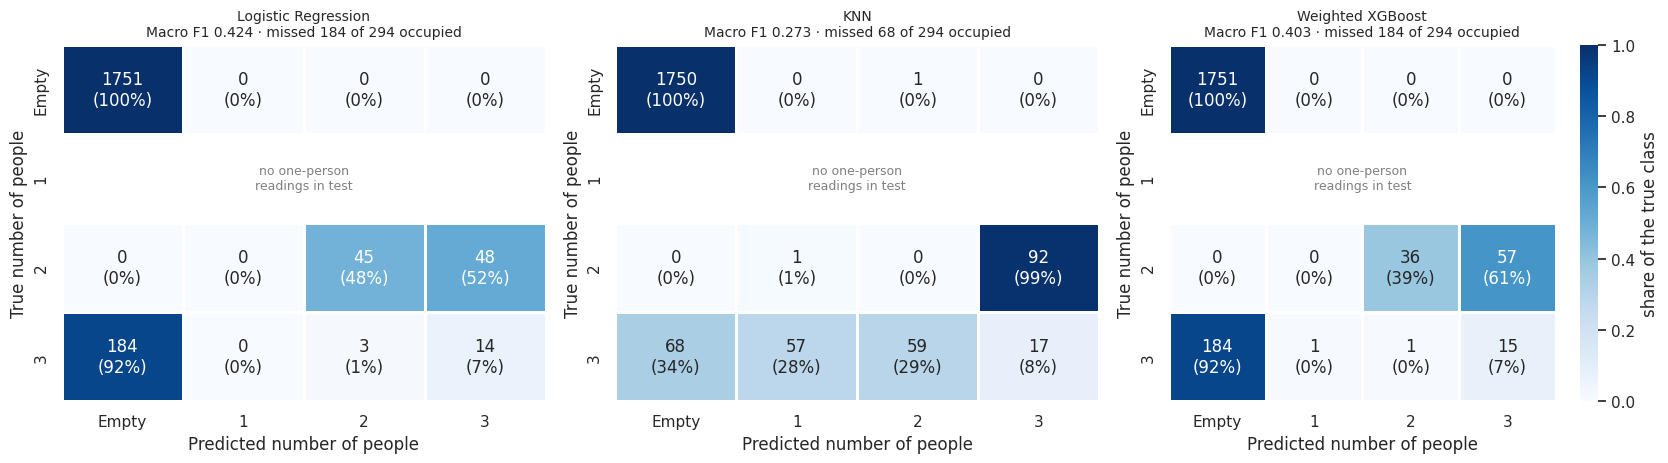

,Occupied readings,Predicted empty (missed),"Occupied, wrong count","Occupied, exact count","Empty, flagged occupied",Missed with S1_Light <= 15
Model,,,,,,
Logistic Regression,294,184,51,59,0,184
KNN,294,68,209,17,1,68
Weighted XGBoost,294,184,59,51,0,184


In [81]:
# Confusion matrices of the three tuned models on the test set (same models as in the table above)
three_models = {
    "Logistic Regression": best_models["Logistic Regression"].predict(X_test_C),
    "KNN": best_models["KNN"].predict(X_test_C),
    "Weighted XGBoost": weighted_xgb_model.predict(X_test_C),
}
LABELS = [0, 1, 2, 3]
class_names = ["Empty", "1", "2", "3"]
occupied_test = y_test > 0

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, (name, pred) in zip(axes, three_models.items()):
    cm = confusion_matrix(y_test, pred, labels=LABELS)
    row_total = cm.sum(axis=1, keepdims=True)
    share = np.divide(cm, row_total, out=np.full(cm.shape, np.nan), where=row_total > 0)   # recall per true class
    annot = np.array([[f"{cm[i, j]}\n({share[i, j]:.0%})" if row_total[i, 0] > 0 else "" for j in range(4)] for i in range(4)])
    sns.heatmap(share, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=(ax is axes[-1]),
                cbar_kws={"label": "share of the true class"}, linewidths=1, linecolor="white",
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.grid(False)
    ax.text(2, 1.5, "no one-person\nreadings in test", ha="center", va="center", fontsize=9, color="gray")
    missed = int(((pred == 0) & occupied_test).sum())
    ax.set_title(f"{name}\nMacro F1 {f1_score(y_test, pred, labels=LABELS, average='macro', zero_division=0):.3f}"
                 f" · missed {missed} of {int(occupied_test.sum())} occupied", fontsize=10)
    ax.set_xlabel("Predicted number of people")
    ax.set_ylabel("True number of people")
plt.tight_layout()
plt.show()

# Where do the errors go?
error_rows = []
for name, pred in three_models.items():
    error_rows.append({
        "Model": name,
        "Occupied readings": int(occupied_test.sum()),
        "Predicted empty (missed)": int(((pred == 0) & occupied_test).sum()),
        "Occupied, wrong count": int(((pred > 0) & occupied_test & (pred != y_test)).sum()),
        "Occupied, exact count": int(((pred == y_test) & occupied_test).sum()),
        "Empty, flagged occupied": int(((pred > 0) & ~occupied_test).sum()),
        f"Missed with S1_Light <= {LIGHT_OFF_LUX}": int(((pred == 0) & occupied_test & (X_test["S1_Light"] <= LIGHT_OFF_LUX)).sum()),
    })
pd.DataFrame(error_rows).set_index("Model")

**Reading the three matrices**

- **Empty rooms are almost never flagged as occupied:** at most 1 of 1,751 empty readings (KNN).
- **Logistic Regression and weighted XGBoost both miss 184 of the 294 occupied readings**, all of them three-person readings. For Logistic Regression these are exactly the readings with `S1_Light` at or below 15 lux (last column of the table). Both models use Feature Set C, and their missed-occupancy errors are strongly associated with low-light readings. However, further controlled experiments are needed to establish how much the light features individually contribute to these errors.
- **KNN misses far fewer (68), but it almost never gets the count right.** Only 17 of the 294 occupied readings get the correct count and 209 get a wrong occupied count: 92 of the 93 two-person readings are predicted as 3 people, and more than half of the three-person readings are predicted as 1 or 2. Its low missed-occupancy comes from spreading predictions across the occupied classes, which is why its Macro F1 (0.27) is the lowest of the three.
- **Two-person readings:** Logistic Regression and XGBoost get about half or fewer right and send the rest to class 3.
- **One-person recognition cannot be judged** from these matrices.

The trade-off between the best Macro F1 (Logistic Regression) and the fewest missed occupied readings (KNN) is the input for the model-selection decision in 5.2.


---
## 5.1 — Error Analysis and Research Findings

The goal of error analysis is to understand why
the models make incorrect predictions.

We investigate:

1. Per-class recall and confusion patterns.
2. Missed occupancy versus incorrect headcounts.
3. The relationship between lighting and errors.
4. Three representative failure cases.

The January test period has already been examined
during model development. The following analysis
is descriptive and is not used for further tuning.

Class 1 is absent from January, so its recall
cannot be measured in this evaluation.


In [82]:

# 5.1 — Per-class recall comparison

from sklearn.metrics import recall_score, f1_score
import pandas as pd
import numpy as np

LABELS = [0, 1, 2, 3]

recall_rows = []

for name, pred in three_models.items():

    recalls = recall_score(
        y_test,
        pred,
        labels=LABELS,
        average=None,
        zero_division=0
    )

    row = {
        "Model": name,
        "Macro F1": f1_score(
            y_test,
            pred,
            labels=LABELS,
            average="macro",
            zero_division=0
        )
    }

    for label, recall in zip(LABELS, recalls):
        support = (y_test == label).sum()

        row[f"Class {label} Recall"] = (
            recall if support > 0 else np.nan
        )

    recall_rows.append(row)

recall_table = pd.DataFrame(recall_rows)

display(recall_table.round(4))


,Model,Macro F1,Class 0 Recall,Class 1 Recall,Class 2 Recall,Class 3 Recall
0,Logistic Regression,0.4237,1.0000,NaN,0.4839,0.0697
1,KNN,0.2726,0.9994,NaN,0.0000,0.0846
2,Weighted XGBoost,0.4035,1.0000,NaN,0.3871,0.0746


In [83]:

# 5.1 — Lighting conditions vs missed occupancy

LIGHT_THRESHOLD = 15

light = X_test["S1_Light"]

occupied = y_test > 0

lighting_groups = {
    "Low light (<=15 lux)": occupied & (
        light <= LIGHT_THRESHOLD
    ),
    "Higher light (>15 lux)": occupied & (
        light > LIGHT_THRESHOLD
    )
}

lighting_rows = []

for model_name, pred in three_models.items():

    pred = pd.Series(pred, index=y_test.index)

    for group_name, mask in lighting_groups.items():

        total = int(mask.sum())

        missed = int(
            ((pred == 0) & mask).sum()
        )

        lighting_rows.append({
            "Model": model_name,
            "Lighting": group_name,
            "Occupied Readings": total,
            "Missed": missed,
            "Missed Rate": (
                missed / total if total else np.nan
            )
        })

lighting_results = pd.DataFrame(lighting_rows)

display(lighting_results.round(4))


,Model,Lighting,Occupied Readings,Missed,Missed Rate
0,Logistic Regression,Low light (<=15 lux),184,184,1.0000
1,Logistic Regression,Higher light (>15 lux),110,0,0.0000
2,KNN,Low light (<=15 lux),184,68,0.3696
3,KNN,Higher light (>15 lux),110,0,0.0000
4,Weighted XGBoost,Low light (<=15 lux),184,184,1.0000
5,Weighted XGBoost,Higher light (>15 lux),110,0,0.0000


In [84]:

# 5.1 — Representative failure cases

# Prepare prediction columns
errors_df = test_df.copy()

errors_df["LR_Pred"] = three_models[
    "Logistic Regression"
]

errors_df["KNN_Pred"] = three_models["KNN"]

errors_df["XGB_Pred"] = three_models[
    "Weighted XGBoost"
]

display_cols = [
    "datetime",
    "Room_Occupancy_Count",
    "S1_Light",
    "S5_CO2",
    "S5_CO2_Slope",
    "S6_PIR",
    "S7_PIR",
    "LR_Pred",
    "KNN_Pred",
    "XGB_Pred"
]

# Case 1: Someone is present in low light,
# but Logistic Regression predicts empty
case1 = errors_df[
    (errors_df["Room_Occupancy_Count"] > 0) &
    (errors_df["S1_Light"] <= 15) &
    (errors_df["LR_Pred"] == 0)
]

# Case 2: KNN detects occupancy,
# but predicts the wrong number of people
case2 = errors_df[
    (errors_df["Room_Occupancy_Count"] > 0) &
    (errors_df["KNN_Pred"] > 0) &
    (
        errors_df["KNN_Pred"] !=
        errors_df["Room_Occupancy_Count"]
    )
]

# Case 3: Two people are present,
# but Logistic Regression predicts three
case3 = errors_df[
    (errors_df["Room_Occupancy_Count"] == 2) &
    (errors_df["LR_Pred"] == 3)
]

print("CASE 1: Occupied but predicted empty")
display(case1[display_cols].head(3))

print("\nCASE 2: KNN predicts wrong headcount")
display(case2[display_cols].head(3))

print("\nCASE 3: Two people predicted as three")
display(case3[display_cols].head(3))


CASE 1: Occupied but predicted empty


,datetime,Room_Occupancy_Count,S1_Light,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,LR_Pred,KNN_Pred,XGB_Pred
8084,2018-01-10 15:25:48,3,10,370,0.184615,1,1,0,1,0
8085,2018-01-10 15:26:19,3,10,370,0.353846,0,1,0,0,0
8086,2018-01-10 15:26:49,3,10,370,0.507692,0,0,0,0,0



CASE 2: KNN predicts wrong headcount


,datetime,Room_Occupancy_Count,S1_Light,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,LR_Pred,KNN_Pred,XGB_Pred
8084,2018-01-10 15:25:48,3,10,370,0.184615,1,1,0,1,0
8088,2018-01-10 15:27:51,3,10,370,0.769231,1,0,0,1,0
8089,2018-01-10 15:28:21,3,10,370,0.876923,1,0,0,1,0



CASE 3: Two people predicted as three


,datetime,Room_Occupancy_Count,S1_Light,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,LR_Pred,KNN_Pred,XGB_Pred
8283,2018-01-10 17:08:56,2,148,785,1.673077,1,1,3,3,3
8284,2018-01-10 17:09:27,2,148,785,1.573077,0,1,3,3,3
8285,2018-01-10 17:09:58,2,148,795,1.538462,1,1,3,3,3



### 5.1 — Error Analysis Findings

**1. Overall Performance**

The three tuned models exhibit different
trade-offs on the January test session.

- Logistic Regression: Macro F1 = 0.4212,
  missed occupancy = 62.59%.
- KNN: Macro F1 = 0.2726,
  missed occupancy = 23.13%.
- Weighted XGBoost: Macro F1 = 0.4035,
  missed occupancy = 62.59%.

**2. Per-Class Performance**

The confusion matrices and recall table show
differences in how models identify empty rooms,
two-person occupancy, and three-person occupancy.

Class-1 recall is unavailable because January
contains no one-person observations.

**3. Lighting Conditions**

Logistic Regression and weighted XGBoost each
missed 184 occupied readings. These missed
readings occurred in low-light conditions.

This suggests that changes in recording
conditions may affect generalization.

However, this association does not establish
lighting as the sole cause of model errors.

**4. Representative Failure Cases**

Case 1: An occupied room is predicted as empty
under low-light conditions.

Case 2: KNN detects occupancy but predicts
the wrong number of people.

Case 3: Logistic Regression confuses
two-person occupancy with three-person occupancy.

**5. Research Questions**

Q1: Adding CO2 slope generally improves
detection of quiet occupants compared with
CO2 alone in the evaluated experiments.

Q2: Adding the remaining sensors improves
separation between one and two people
during December validation.

However, the improvements do not generalize
consistently to the January session.

**6. Limitations**

- January has no class-1 observations.
- Only one short occupied January session exists.
- The test set was examined repeatedly.
- Differences in room conditions may affect results.
- Error associations do not necessarily imply causation.

**Conclusion**

No model is best across every metric.

Logistic Regression achieves higher four-class
Macro F1 on January, while KNN has fewer
missed occupied readings.

The final decision in Section 5.2 should
consider these trade-offs alongside
training-period validation results,
complexity, and deployment requirements.



---
## 5.2 — Final Model Selection and Saving

### Selected Model

**Tuned Logistic Regression — Feature Set C**

We selected this model for the four-class room
occupancy classification prototype.

### Selection Rationale

1. The default Logistic Regression with Feature
   Set C achieved the highest four-fold CV Macro F1
   (0.553) among the 12 combinations.

2. It achieved the highest forward-day Macro F1
   (0.9905) during December 22 → 23 validation.

3. Its forward-day missed occupancy rate was 0%,
   with a false alarm rate of approximately 0.1%.

4. Logistic Regression is simple, fast and
   suitable for deployment through FastAPI.

### Tuned Configuration

- Model: Logistic Regression
- Preprocessing: StandardScaler
- Class weight: balanced
- C: 1.0129197956845732
- Feature set: C (all 16 sensor features)
- Tuned CV Macro F1: 0.55398

### Limitations

The January session contained low-light occupied
readings that this model frequently classified
as empty.

The tuned model missed 62.59% of occupied
January observations.

Therefore, the selected model is suitable
as a research prototype, but its reliability
under different environmental conditions
remains unproven.

The January session has already been examined
repeatedly and is treated as descriptive evidence.

### Deployment

The complete fitted preprocessing and
classification pipeline will be saved using joblib,
alongside the feature names and input schema.


In [85]:
lr_search.best_estimator_

Pipeline(steps=[('scaler', StandardScaler()),
                ('model',
                 LogisticRegression(C=np.float64(1.0129197956845732),
                                    class_weight='balanced', max_iter=2000,
                                    random_state=42))])

In [86]:

# 5.2 — Select and save final model

from sklearn.base import clone
from pathlib import Path
import joblib
import json
import numpy as np

# Create models folder
model_dir = Path("models")
model_dir.mkdir(parents=True, exist_ok=True)

# Selected model: Tuned Logistic Regression
# Feature Set C: all 16 sensors
selected_features = list(features_C)

# Clone tuned configuration (without fitted state)
final_model = clone(lr_search.best_estimator_)

# Train on December data only
final_model.fit(
    X_train[selected_features],
    y_train
)

# Save complete pipeline (scaler + classifier)
joblib.dump(
    final_model,
    model_dir / "model.joblib"
)

# Save feature names in exact training order
joblib.dump(
    selected_features,
    model_dir / "features.joblib"
)

# Save model metadata
metadata = {
    "model": "Logistic Regression",
    "feature_set": "C",
    "features": selected_features,
    "classes": final_model.classes_.tolist(),
    "best_params": {
        "C": float(
            lr_search.best_params_["model__C"]
        )
    },
    "preprocessing": "StandardScaler",
    "training_period": "December 2017",
    "intended_use": "Research prototype"
}

with open(
    model_dir / "metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(metadata, f, indent=4)

print("Final model saved successfully!")
print("Model:", model_dir / "model.joblib")
print("Features:", model_dir / "features.joblib")
print("Metadata:", model_dir / "metadata.json")

print("\nNumber of features:", len(selected_features))
print("Classes:", final_model.classes_)


Final model saved successfully!
Model: models/model.joblib
Features: models/features.joblib
Metadata: models/metadata.json

Number of features: 16
Classes: [0 1 2 3]


In [87]:

# 5.2 — Reload and verify saved model

import joblib
import numpy as np
import pandas as pd

# Load saved artifacts
loaded_model = joblib.load(
    "models/model.joblib"
)

loaded_features = joblib.load(
    "models/features.joblib"
)

# Check feature order
assert loaded_features == selected_features

assert list(loaded_model.feature_names_in_) == (
    loaded_features
)

# Use 10 training examples for a reload test
sample = X_train[loaded_features].head(10)

# Predictions before saving
original_predictions = final_model.predict(sample)

# Predictions after loading
loaded_predictions = loaded_model.predict(sample)

# Predictions must match
np.testing.assert_array_equal(
    original_predictions,
    loaded_predictions
)

# Probabilities must match
np.testing.assert_allclose(
    final_model.predict_proba(sample),
    loaded_model.predict_proba(sample)
)

print("Model verification PASSED!")
print("Feature order verified:", True)
print("Predictions match:", True)

display(pd.DataFrame({
    "Before Saving": original_predictions,
    "After Loading": loaded_predictions
}))


Model verification PASSED!
Feature order verified: True
Predictions match: True


,Before Saving,After Loading
0,1,1
1,1,1
2,1,1
3,1,1
4,1,1
5,1,1
6,1,1
7,1,1
8,1,1
9,1,1


In [88]:

# 5.2 — Generate example API input and output

import json
import numpy as np
import pandas as pd

# Example sensor reading from training data
sample_input = X_train[
    loaded_features
].iloc[0]

# Convert values to regular Python numbers
input_json = {
    feature: float(sample_input[feature])
    for feature in loaded_features
}

# Create DataFrame in training feature order
input_df = pd.DataFrame(
    [input_json],
    columns=loaded_features
)

# Make prediction
prediction = int(
    loaded_model.predict(input_df)[0]
)

# Get probabilities
probabilities = loaded_model.predict_proba(
    input_df
)[0]

probability_map = {
    str(int(label)): round(float(prob), 4)
    for label, prob in zip(
        loaded_model.classes_,
        probabilities
    )
}

# Example API response
output_json = {
    "count": prediction,
    "occupied": bool(prediction > 0),
    "probabilities": probability_map
}

# Save input example
with open(
    "models/example_input.json",
    "w"
) as f:
    json.dump(input_json, f, indent=4)

# Save output example
with open(
    "models/example_output.json",
    "w"
) as f:
    json.dump(output_json, f, indent=4)

print("=== Example API Input ===")
print(json.dumps(input_json, indent=4))

print("\n=== Example API Output ===")
print(json.dumps(output_json, indent=4))


=== Example API Input ===
{
    "S1_Temp": 24.94,
    "S2_Temp": 24.75,
    "S3_Temp": 24.56,
    "S4_Temp": 25.38,
    "S1_Light": 121.0,
    "S2_Light": 34.0,
    "S3_Light": 53.0,
    "S4_Light": 40.0,
    "S1_Sound": 0.08,
    "S2_Sound": 0.19,
    "S3_Sound": 0.06,
    "S4_Sound": 0.06,
    "S5_CO2": 390.0,
    "S5_CO2_Slope": 0.769230769231,
    "S6_PIR": 0.0,
    "S7_PIR": 0.0
}

=== Example API Output ===
{
    "count": 1,
    "occupied": true,
    "probabilities": {
        "0": 0.0037,
        "1": 0.9957,
        "2": 0.0006,
        "3": 0.0
    }
}



### Final Selected Model

For the four-class classification prototype,
we selected tuned Logistic Regression with
Feature Set C.

The decision is primarily based on the
development-validation evidence, including
Macro F1, missed occupancy, false alarms,
model complexity, and deployment simplicity.

The complete fitted pipeline was saved as:

`models/model.joblib`

The ordered 16-feature input schema was saved as:

`models/features.joblib`

The saved model was reloaded and verified to
produce identical predictions and probabilities.

**Deployment limitation:**

The selected model performs poorly on the
low-light occupied readings in January.
Deployment is therefore intended for demonstration
and research, not unattended room-availability
decisions.


### Modeling Results and Conclusion

Several classification models were tested using three feature sets. The results showed that using all sensor features (Feature Set C) generally improved model performance compared to using CO2 alone or CO2 with its slope.

Logistic Regression achieved the highest test Macro F1 score of 0.4212, making it the strongest model in terms of overall class balance. However, it missed 184 occupied readings.

KNN had a lower Macro F1 score of 0.2726, but it missed only 68 occupied readings, which was the lowest among the tested models.

Weighted XGBoost achieved a test Macro F1 score of 0.4035. Although class weighting improved its cross-validation performance, it did not outperform Logistic Regression on the test set.

Overall, Logistic Regression provided the best Macro F1 result, while KNN was better at detecting occupied rooms. This shows that model selection depends on the main project objective.

One important limitation is that Class 1 was not represented in the test set, so the models' ability to detect a single person could not be evaluated using the final test results.

> **Note on the conclusion above (added after the comparison in 4.2).** The statement that feature set C improves performance holds for the cross-validation Macro F1. On the test days it does not hold for missed occupancy: set B (CO₂ + slope) gives low missed occupancy without many false alarms, while the models built on set C miss many occupied readings because the test session has people with the lights nearly off (see 3.1b and the comparison in 4.2). The absence of class 1 from the test set is documented in 3.1b.

### Tricky Moments Exploration (Test Set)

In [89]:
co2_moments = test_df[
    test_df["S5_CO2"].between(385, 395)
].copy()

co2_moments["Slope_Sign"] = np.where(
    co2_moments["S5_CO2_Slope"] > 0, "Positive",
    np.where(
        co2_moments["S5_CO2_Slope"] < 0, "Negative",
        "Zero"
    )
)

co2_summary = co2_moments.groupby(
    ["Room_Occupancy_Count", "Slope_Sign"]
).size().unstack(fill_value=0)

display(co2_summary)

Slope_Sign,Negative,Positive,Zero
Room_Occupancy_Count,,,
0,47,0,7
3,0,5,0


In [90]:
quiet_moments = test_df[
    (test_df["S6_PIR"] == 0) &
    (test_df["S7_PIR"] == 0) &
    (test_df["Room_Occupancy_Count"] > 0)
].copy()

print("Quiet Occupant Moments:", len(quiet_moments))

display(
    quiet_moments[
        [
            "datetime",
            "S5_CO2",
            "S5_CO2_Slope",
            "S6_PIR",
            "S7_PIR",
            "Room_Occupancy_Count"
        ]
    ].head(10)
)

Quiet Occupant Moments: 59


,datetime,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
8086,2018-01-10 15:26:49,370,0.507692,0,0,3
8092,2018-01-10 15:29:53,370,1.107692,0,0,3
8093,2018-01-10 15:30:24,370,1.153846,0,0,3
8095,2018-01-10 15:31:25,370,1.200000,0,0,3
8096,2018-01-10 15:31:56,370,1.200000,0,0,3
8097,2018-01-10 15:32:26,370,1.184615,0,0,3
8098,2018-01-10 15:32:57,370,1.153846,0,0,3
8099,2018-01-10 15:33:28,370,1.107692,0,0,3
8100,2018-01-10 15:33:58,370,1.046154,0,0,3
8110,2018-01-10 15:39:04,370,0.000000,0,0,3


In [91]:
from pathlib import Path
from google.colab import files
import shutil, joblib, json

required = ["model.joblib", "features.joblib", "metadata.json",
            "example_input.json", "example_output.json"]
for file in required:
    assert (Path("models") / file).exists(), f"Missing: {file}"

model = joblib.load("models/model.joblib")  # your own trusted artifact
features = joblib.load("models/features.joblib")
assert len(features) == 16
assert list(model.feature_names_in_) == list(features)
print("Model classes:", model.classes_)
print("Ordered features:", features)

shutil.make_archive("occupancy_model_handoff", "zip", root_dir=".", base_dir="models")
files.download("occupancy_model_handoff.zip")

Model classes: [0 1 2 3]
Ordered features: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>